# 🎬 Il successo nell'audiovisivo 2000-2025: gradimento del pubblico e premi
### Progetto Capstone – Master Data Analyst, Epicode · Francesco Autorino

In questo progetto analizzo film, serie TV e miniserie usciti tra il 2000 e il 2025 da due punti di vista:

- il **pubblico**: voto medio e numero di voti su IMDb;
- i **premi**: candidature e vittorie a Oscar, Golden Globe ed Emmy.

Per brevità chiamo "critica" le giurie dei tre premi. In realtà non sono critici in senso stretto: gli Oscar
li assegnano i professionisti del cinema dell'Academy, i Golden Globe i giornalisti, gli Emmy la Television Academy.

Le domande a cui provo a rispondere sono tre:

1. Come si distribuiscono gradimento, voti e generi di film, serie e miniserie, e quanti titoli ricevono candidature?
2. Pubblico e critica vanno d'accordo? I titoli candidati ai premi sono anche quelli più graditi? Miniserie e serie TV si comportano in modo diverso?
3. Per le serie TV: come cambia il gradimento stagione dopo stagione? E l'ultima stagione è davvero gradita meno delle precedenti?

**Fonti**

| Dati | Fonte |
|---|---|
| Film, serie, episodi, voti, cast e registi | IMDb Non-Commercial Datasets |
| Popolarità, lingua, paesi, case di produzione, budget | TMDB (Kaggle, aggiornato al 2025) |
| Oscar | The Oscar Award (Kaggle) |
| Golden Globe | Golden Globe Awards (Kaggle) + edizioni 2021-2025 da Wikipedia |
| Emmy | TidyTuesday ed Emmy Awards (Kaggle) + edizioni recenti da Wikipedia |

**Struttura del notebook:** 1 Configurazione · 2 Catalogo IMDb · 3 Collegamento dei premi (con controllo a campione) ·
4 Tabelle finali · 5 Cast e premi delle persone · 6 Esplorazione (con modello di regressione) ·
7 Approfondimento sulle serie · 8 Tabelle per Power BI · 9 Conclusioni

## ⚙️ 1. Configurazione

Librerie, percorsi e i parametri principali del progetto. I file grezzi stanno nella cartella
`DataSetProgettoCapStone/Grezzi`, le tabelle pulite vengono salvate in `CSVCreati/` e quelle per la dashboard in `powerbi/`.

Nella prima cella di codice controllo che ci siano tutte le librerie che uso. Lavoro con Anaconda, che le ha già
quasi tutte: manca solo `rapidfuzz`. Se una libreria manca la installo con `conda` (canale conda-forge), e con `pip`
solo se il notebook non gira in un ambiente conda. Le istruzioni complete per l'installazione sono nel README.

I file scaricati li ho rinominati con nomi più leggibili: la corrispondenza con i nomi originali è qui sotto nei
commenti e nel README.

In [1]:
# controllo che ci siano tutte le librerie che uso (con Anaconda manca solo rapidfuzz)
import os
import sys
import importlib.util

LIBRERIE = ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "statsmodels", "rapidfuzz"]
mancanti = [libreria for libreria in LIBRERIE if importlib.util.find_spec(libreria) is None]
da_installare = " ".join(mancanti)

if not mancanti:
    print("Tutte le librerie sono già installate")
elif os.path.exists(os.path.join(sys.prefix, "conda-meta")):
    # sono in Anaconda: installo con conda nell'ambiente del kernel
    print("Installo con conda:", da_installare)
    %conda install -y -c conda-forge $da_installare
else:
    # niente conda (per esempio Google Colab): installo con pip
    print("Installo con pip:", da_installare)
    %pip install -q $da_installare

Tutte le librerie sono già installate


In [2]:
import os
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rapidfuzz import process, fuzz
from scipy import stats
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

RAW = "../DataSetProgettoCapStone/Grezzi/"
OUT = "CSVCreati/"
OUT_PBI = "powerbi/"
os.makedirs(OUT, exist_ok=True)
os.makedirs(OUT_PBI, exist_ok=True)

# file grezzi (nome usato qui  <-  nome originale)
#   title.basics.tsv                                  <- IMDb title.basics.tsv
#   IMDb - Voti e rating.tsv                          <- IMDb title.ratings.tsv
#   IMDb - Elenco episodi.tsv                         <- IMDb title.episode.tsv
#   IMDb - Nomi delle persone.tsv                     <- IMDb name.basics.tsv
#   IMDb - Registi e sceneggiatori.tsv                <- IMDb title.crew.tsv
#   IMDb - Cast principale.tsv                        <- IMDb title.principals.tsv
#   TMDB - Film aggiornati al 2025.csv                <- Kaggle TMDB_movie_dataset_v11.csv
#   Premi Oscar 1927-2025.csv                         <- Kaggle the_oscar_award.csv
#   Golden Globe 1944-2025.csv                        <- Kaggle golden_globe_awards.csv + edizioni 2021-2025 da Wikipedia
#   Emmy 1949-2025, per serie TV.csv                  <- TidyTuesday nominees.csv + edizioni 2022-2025 da Wikipedia
#   Emmy 1949-2019, con nome attore o regista.csv     <- Kaggle the_emmy_awards.csv
#   Emmy 2020-2025, con nome attore o regista (...)   <- edizioni 2020-2025 da Wikipedia

# periodo e soglia di visibilità
ANNO_MIN, ANNO_MAX = 2000, 2025
SOGLIA_VOTI = 1000

# parametri del fuzzy matching
SOGLIA_TITOLO = 90          # somiglianza minima tra i titoli (0-100)
SOGLIA_ORDINE = 85          # somiglianza minima rispettando l'ordine delle parole
SOGLIA_PERSONA = 85         # somiglianza minima tra i nomi delle persone
MARGINE_AMBIGUITA = 5       # distacco minimo tra il primo e il secondo candidato
TOLLERANZA_ANNI = 1         # un film può essere premiato l'anno dopo l'uscita
RAPPORTO_VOTI = 3           # spareggio tra titoli omonimi: vince chi ha almeno 3 volte i voti
ANNO_EMMY_WIKIPEDIA = 2022  # da quest'anno le righe Emmy per serie vengono da Wikipedia

# controllo a campione dei collegamenti
N_CAMPIONE_CONTROLLO = 100  # collegamenti da verificare a mano (metà con titolo identico, metà solo simile)
SEED = 42                   # per estrarre sempre lo stesso campione

# approfondimento sulle serie
MIN_STAGIONI = 4
FASI = ["Inizio (0-20%)", "20-40%", "40-60%", "60-80%", "Finale (80-100%)"]

In [3]:
def normalizza_testo(s):
    # minuscole, senza accenti e punteggiatura, & -> and
    if pd.isna(s):
        return ""
    s = re.sub(r"[·•・]", " ", str(s))        # WALL·E -> wall e (come WALL-E)
    s = re.sub(r"[‘’ʼ`´]", " ", s)
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode("ascii")
    s = s.lower().replace("&", " and ")
    s = re.sub(r"[^a-z0-9]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def senza_articoli(s):
    return " ".join(w for w in str(s).split() if w not in {"the", "a", "an"})


def vinto_bool(x):
    if pd.isna(x):
        return False
    if isinstance(x, str):
        return x.strip().lower() in ("true", "1", "yes", "winner")
    return bool(x)


def nel_periodo(anni):
    anni = pd.to_numeric(anni, errors="coerce")
    return anni.between(ANNO_MIN - TOLLERANZA_ANNI, ANNO_MAX + TOLLERANZA_ANNI)


def salva(df, nome):
    df.to_csv(OUT + nome, index=False)
    print(f"{nome}: {len(df)} righe")

## 🎞️ 2. Catalogo IMDb: film, serie TV, miniserie ed episodi

Parto da `title.basics` di IMDb, che è molto grande, quindi lo leggo a blocchi e tengo solo film, serie e miniserie
usciti tra il 2000 e il 2025. Poi aggiungo voti e rating e tengo solo i titoli con **almeno 1.000 voti**: senza questa
soglia il catalogo sarebbe pieno di produzioni minori che nessuno ha visto.

Il file IMDb usa le virgolette come carattere normale nei titoli, per questo lo leggo con `quoting=3`.

In [4]:
TIPI = ["movie", "tvSeries", "tvMiniSeries"]
COLONNE = ["tconst", "titleType", "primaryTitle", "originalTitle", "startYear", "endYear", "runtimeMinutes", "genres"]

blocchi = []
for b in pd.read_csv(RAW + "title.basics.tsv", sep="\t", dtype=str, na_values="\\N", usecols=COLONNE,
                     quoting=3, chunksize=500_000):
    b = b[b["titleType"].isin(TIPI)]
    b = b[pd.to_numeric(b["startYear"], errors="coerce").between(ANNO_MIN, ANNO_MAX)]
    blocchi.append(b)
basics = pd.concat(blocchi, ignore_index=True)
for col in ["startYear", "endYear", "runtimeMinutes"]:
    basics[col] = pd.to_numeric(basics[col], errors="coerce")

ratings = pd.read_csv(RAW + "IMDb - Voti e rating.tsv", sep="\t", dtype=str, na_values="\\N")
ratings["averageRating"] = pd.to_numeric(ratings["averageRating"])
ratings["numVotes"] = pd.to_numeric(ratings["numVotes"])

basics = basics.merge(ratings, on="tconst", how="left")
movies = basics[basics["titleType"] == "movie"]
series = basics[basics["titleType"] != "movie"]

movies_relevant = movies[movies["numVotes"] >= SOGLIA_VOTI].copy()
series_relevant = series[series["numVotes"] >= SOGLIA_VOTI].copy()

print("Titoli IMDb 2000-2025:", basics["titleType"].value_counts().to_dict())
print("Film con almeno 1.000 voti:", len(movies_relevant))
print("Serie e miniserie con almeno 1.000 voti:", series_relevant["titleType"].value_counts().to_dict())

Titoli IMDb 2000-2025: {'movie': 370506, 'tvSeries': 217957, 'tvMiniSeries': 55632}
Film con almeno 1.000 voti: 32240
Serie e miniserie con almeno 1.000 voti: {'tvSeries': 8421, 'tvMiniSeries': 2226}


**Episodi.** Prendo gli episodi delle serie rimaste e il loro rating. L'anno di uscita degli episodi è sempre in
`title.basics` (righe `tvEpisode`), quindi rileggo il file solo per quelli. Tengo gli episodi usciti tra il 2000 e
il 2025 e quelli senza anno (quasi sempre episodi annunciati). Conto quanti episodi perde ogni serie: se una serie
conclusa perde episodi, la sua ultima stagione nei dati non è il vero finale e non la userò nell'analisi delle stagioni.

In [5]:
episodes_raw = pd.read_csv(RAW + "IMDb - Elenco episodi.tsv", sep="\t", dtype=str, na_values="\\N")
episodes = episodes_raw[episodes_raw["parentTconst"].isin(set(series_relevant["tconst"]))].copy()
episodes = episodes.merge(ratings, on="tconst", how="left")
episodes["seasonNumber"] = pd.to_numeric(episodes["seasonNumber"], errors="coerce")
episodes["episodeNumber"] = pd.to_numeric(episodes["episodeNumber"], errors="coerce")

# anno di uscita degli episodi
ids_episodi = set(episodes["tconst"])
blocchi = []
for b in pd.read_csv(RAW + "title.basics.tsv", sep="\t", dtype=str, na_values="\\N", quoting=3,
                     usecols=["tconst", "titleType", "startYear"], chunksize=500_000):
    blocchi.append(b[(b["titleType"] == "tvEpisode") & b["tconst"].isin(ids_episodi)][["tconst", "startYear"]])
anno_episodio = pd.concat(blocchi).drop_duplicates("tconst").set_index("tconst")["startYear"]
episodes["episode_year"] = pd.to_numeric(episodes["tconst"].map(anno_episodio), errors="coerce")

fuori = (episodes["episode_year"] < ANNO_MIN) | (episodes["episode_year"] > ANNO_MAX)
episodi_fuori_periodo = episodes[fuori].groupby("parentTconst").size()
episodes = episodes[~fuori].copy()

print("Episodi delle serie del catalogo:", len(episodes) + fuori.sum())
print("Episodi esclusi perché usciti fuori dal periodo:", fuori.sum(), "- serie coinvolte:", len(episodi_fuori_periodo))
print("Episodi senza anno:", episodes["episode_year"].isna().sum())
print(f"Episodi con rating: {episodes['averageRating'].notna().mean():.1%}")

Episodi delle serie del catalogo: 652532
Episodi esclusi perché usciti fuori dal periodo: 13738 - serie coinvolte: 919
Episodi senza anno: 37155
Episodi con rating: 55.1%


## 🔗 3. Collegamento dei premi ai titoli

Le fonti dei premi non hanno l'identificativo IMDb, quindi ho collegato le candidature ai titoli confrontando
**titolo e anno** con il fuzzy matching (`rapidfuzz`). Una candidatura viene collegata solo se:

- il titolo è abbastanza simile (punteggio ≥ 90 su 100) a un titolo del catalogo uscito nello stesso anno (±1 anno);
  per le serie conta ogni anno di messa in onda;
- il secondo titolo più simile è staccato di almeno 5 punti, altrimenti il collegamento è ambiguo e lo scarto;
- le parole sono nello stesso ordine ("Day One" non è "One Day").

Controllando a mano sui siti ufficiali dei premi i collegamenti con il punteggio più basso ho trovato alcuni errori
ricorrenti e ho aggiunto delle regole per correggerli:

- confronto sia il titolo principale sia quello originale e, solo se non basta, alcune varianti: senza parentesi,
  con l'articolo spostato ("Office, The"), senza sottotitolo per i film ("Lagaan: Once Upon a Time in India");
- tra due titoli omonimi con lo stesso punteggio scelgo quello con almeno tre volte i voti dell'altro ("The Killing" del 2011);
- le categorie TV senza una serie corrispondente cercano tra i film (film per la TV e documentari), ma solo con titolo identico;
- gli speciali promozionali ("Inside Look: ...") e i cortometraggi degli Oscar non si collegano;
- per gli Emmy l'opera non può uscire dopo la cerimonia, e per le categorie Short Form serve il titolo identico.

Una candidatura non collegata non vuol dire che il titolo non l'abbia ricevuta: vuol dire che il collegamento non era
abbastanza sicuro. Per questo i conteggi dei premi sono un **minimo**.

In [6]:
CATEGORIE_ANCHE_FILM = "Limited|Miniseries|Mini-Series|Movie|Motion Picture|Special|Anthology|Nonfiction|Documentary"
CATEGORIE_SOLO_TITOLO_INTERO = "Short[- ]Form|Short[- ]Format"
CATEGORIE_NONFICTION = "Nonfiction|Non-Fiction|Documentary|Narrator|Reality"
CATEGORIE_VARIETA = "Variety|Stand-Up|Music Direction|Music Supervision"
SPECIALI = ["inside look"]


def genere_coerente(categoria, generi):
    # una categoria documentaristica vuole un documentario, una di varietà un documentario, un concerto o una commedia
    generi = str(generi)
    if re.search(CATEGORIE_NONFICTION, str(categoria), flags=re.I):
        return "Documentary" in generi
    if re.search(CATEGORIE_VARIETA, str(categoria), flags=re.I):
        return "Documentary" in generi or "Music" in generi or generi == "Comedy"
    return True


def varianti_catalogo(titolo):
    # titolo intero, senza sottotitolo e senza "Episode IV"
    v = {normalizza_testo(titolo)}
    if isinstance(titolo, str) and ":" in titolo:
        v.add(normalizza_testo(titolo.split(":")[0]))
    v.add(re.sub(r"\s+", " ", re.sub(r"\bepisode [ivxl]+\b", " ", normalizza_testo(titolo))).strip())
    return {t for t in v if t}


def varianti_fonte(testo, senza_parentesi=True):
    # titolo della fonte intero, senza parentesi e con l'articolo finale spostato all'inizio
    t = str(testo)
    v = {t}
    tra_parentesi = normalizza_testo(" ".join(re.findall(r"\(([^()]*)\)", t)))
    if senza_parentesi and not any(p in tra_parentesi for p in SPECIALI):
        v.add(re.sub(r"\s*\([^()]*\)", " ", t))
    m = re.match(r"^(.*),\s*(The|A|An)\s*$", t, flags=re.I)
    if m:
        v.add(f"{m.group(2)} {m.group(1)}")
    return {n for n in (normalizza_testo(x) for x in v) if n}


def costruisci_indice(df, col_inizio, col_fine=None):
    # {anno: [(titolo normalizzato, tconst, è il titolo intero?)]}
    # i film stanno solo nell'anno di uscita, le serie in tutti gli anni di messa in onda
    indice = {}
    for tconst, inizio, fine, principale, originale in zip(
            df["tconst"], df[col_inizio], df[col_fine] if col_fine else [None] * len(df),
            df["primaryTitle"], df["originalTitle"]):
        if pd.isna(inizio):
            continue
        a0 = int(inizio)
        a1 = max(int(fine) if col_fine and pd.notna(fine) else (ANNO_MAX if col_fine else a0), a0)
        interi = {normalizza_testo(principale), normalizza_testo(originale)} - {""}
        # per le serie niente titolo accorciato: la parte prima dei due punti è quasi sempre la serie madre di uno spin-off
        varianti = interi if col_fine else varianti_catalogo(principale) | varianti_catalogo(originale)
        for anno in range(a0, a1 + 1):
            for t in varianti:
                indice.setdefault(anno, []).append((t, tconst, t in interi))
    return indice


indice_film = costruisci_indice(movies_relevant, "startYear")
indice_serie = costruisci_indice(series_relevant, "startYear", "endYear")
VOTI = dict(zip(pd.concat([movies_relevant["tconst"], series_relevant["tconst"]]),
                pd.concat([movies_relevant["numVotes"], series_relevant["numVotes"]])))
GENERI_FILM = dict(zip(movies_relevant["tconst"], movies_relevant["genres"]))
FILM_TITOLO_ORIGINALE_UGUALE = set(movies_relevant.loc[movies_relevant["primaryTitle"].map(normalizza_testo)
                                                       == movies_relevant["originalTitle"].map(normalizza_testo), "tconst"])

In [7]:
def abbina(testo, anno, indice, soglia, con_varianti, senza_parentesi=True, anni_dopo=TOLLERANZA_ANNI):
    # cerca il titolo della fonte tra i titoli del catalogo usciti negli anni vicini
    norm = normalizza_testo(testo)
    risultato = {"imdb_id": None, "punteggio": np.nan}
    if not norm or pd.isna(pd.to_numeric(anno, errors="coerce")):
        return {**risultato, "esito": "dati_mancanti"}
    testi = sorted(varianti_fonte(testo, senza_parentesi)) if con_varianti else [norm]
    a = int(anno)
    ammette_speciali = any(p in norm for p in SPECIALI)
    voci, ids, interi = [], [], []
    for y in range(a - TOLLERANZA_ANNI, a + anni_dopo + 1):
        for t, tconst, intero in indice.get(y, []):
            if (con_varianti or intero) and (ammette_speciali or not any(t.startswith(p) for p in SPECIALI)):
                voci.append(t)
                ids.append(tconst)
                interi.append(intero)
    if not voci:
        return {**risultato, "esito": "nessun_candidato"}

    punteggi_matrice = process.cdist(testi, voci, scorer=fuzz.token_sort_ratio)
    punteggi, quale = punteggi_matrice.max(axis=0), punteggi_matrice.argmax(axis=0)
    migliore, variante, da_intero = {}, {}, {}
    for j, (tconst, p) in enumerate(zip(ids, punteggi)):
        if p > migliore.get(tconst, -1) or (p == migliore[tconst] and interi[j]):
            migliore[tconst], variante[tconst], da_intero[tconst] = float(p), testi[quale[j]], interi[j]
    ordinati = sorted(migliore.items(), key=lambda x: -x[1])
    primo, p1 = ordinati[0]
    p2 = ordinati[1][1] if len(ordinati) > 1 else np.nan
    risultato["punteggio"] = p1
    if p1 < soglia:
        return {**risultato, "esito": "sotto_soglia"}

    if len(ordinati) > 1 and p1 - p2 < MARGINE_AMBIGUITA:
        # spareggio per voti tra titoli con lo stesso punteggio (solo se viene dal titolo intero)
        vicini = [t for t, p in ordinati if p1 - p < MARGINE_AMBIGUITA]
        pari = [t for t, p in ordinati if p == p1]
        piu_votato = max(pari, key=lambda t: VOTI.get(t, 0))
        if not da_intero[piu_votato] or not all(VOTI.get(t, 0) * RAPPORTO_VOTI <= VOTI.get(piu_votato, 0)
                                                for t in vicini if t != piu_votato):
            return {**risultato, "esito": "ambiguo"}
        primo = piu_votato

    # controllo sull'ordine delle parole
    p_ordine = max(fuzz.ratio(senza_articoli(variante[primo]), senza_articoli(v)) for v, t in zip(voci, ids) if t == primo)
    if p_ordine < SOGLIA_ORDINE:
        return {**risultato, "esito": "ordine_parole_diverso"}
    return {"imdb_id": primo, "punteggio": p1, "esito": "collegato"}


def abbina_titoli(df, col_titolo, col_anno, indice, uno_a_uno, indice_film_tv=None, anno_cerimonia=False):
    # collega ogni combinazione (titolo, anno) della fonte; per gli Emmy l'anno è quello della cerimonia,
    # quindi con le varianti l'opera non può uscire dopo
    solo_serie = df["categoria"].astype(str).str.contains("Series", case=False) & \
        ~df["categoria"].astype(str).str.contains(CATEGORIE_ANCHE_FILM, case=False)
    titoli_solo_serie = set(df.loc[solo_serie, col_titolo].map(normalizza_testo))
    categorie = df.groupby([col_titolo, col_anno])["categoria"].agg(list).to_dict()
    anni_dopo = 0 if anno_cerimonia else TOLLERANZA_ANNI

    q = df[[col_titolo, col_anno]].drop_duplicates().rename(columns={col_titolo: "testo", col_anno: "anno"})
    q = q.reset_index(drop=True)
    risultati = []
    for t, a in zip(q["testo"], q["anno"]):
        cat = categorie.get((t, a), [])
        solo_intero = bool(cat) and all(re.search(CATEGORIE_SOLO_TITOLO_INTERO, str(c), flags=re.I) for c in cat)
        # 1) titolo intero
        r = abbina(t, a, indice, SOGLIA_TITOLO, con_varianti=False)
        # 2) se non basta, varianti del titolo
        if r["esito"] != "collegato" and not solo_intero:
            r2 = abbina(t, a, indice, SOGLIA_TITOLO, con_varianti=True, anni_dopo=anni_dopo)
            if r2["esito"] == "collegato":
                r = r2
        # 3) categorie TV senza serie corrispondente: film per la TV, solo con titolo identico
        if (indice_film_tv is not None and r["esito"] in ("sotto_soglia", "nessun_candidato")
                and normalizza_testo(t) not in titoli_solo_serie and not solo_intero):
            r3 = abbina(t, a, indice_film_tv, 100, con_varianti=True, senza_parentesi=False, anni_dopo=anni_dopo)
            if (r3["esito"] == "collegato" and r3["imdb_id"] in FILM_TITOLO_ORIGINALE_UGUALE
                    and all(genere_coerente(c, GENERI_FILM.get(r3["imdb_id"])) for c in cat)):
                r = r3
        risultati.append(r)
    q = pd.concat([q, pd.DataFrame(risultati)], axis=1)

    if uno_a_uno:
        # per i film: se due titoli della fonte puntano allo stesso film resta quello con il punteggio migliore
        collegati = q[q["esito"] == "collegato"]
        tenuti = collegati.sort_values("punteggio", ascending=False).drop_duplicates("imdb_id").index
        scartati = collegati.index.difference(tenuti)
        q.loc[scartati, "esito"] = "conflitto"
        q.loc[scartati, "imdb_id"] = None
    print(f"{len(q)} combinazioni titolo-anno:", q["esito"].value_counts().to_dict())
    return df.merge(q.rename(columns={"testo": col_titolo, "anno": col_anno, "punteggio": "punteggio_match",
                                      "esito": "esito_match"}), on=[col_titolo, col_anno], how="left")


def conta_premi(det, prefisso):
    c = det[det["esito_match"] == "collegato"].groupby("imdb_id").agg(
        **{f"{prefisso}_nominations": ("vinto", "size"), f"{prefisso}_wins": ("vinto", "sum")})
    return c.astype(int)

### 3.1 Oscar

Uso l'anno dell'opera (`year_film`). Le candidature ai cortometraggi non le collego: il catalogo non contiene corti.

In [8]:
oscar = pd.read_csv(RAW + "Premi Oscar 1927-2025.csv")
oscar_det = pd.DataFrame({
    "id_riga_fonte": "oscar_" + oscar.index.astype(str),
    "fonte": "oscar",
    "ambito": "film",
    "categoria": oscar["canon_category"],
    "anno_premio": oscar["year_ceremony"],
    "anno_opera": pd.to_numeric(oscar["year_film"], errors="coerce"),
    "titolo_fonte": oscar["film"],
    "persona_fonte": oscar["name"],
    "vinto": oscar["winner"].map(vinto_bool),
})
oscar_det = oscar_det[nel_periodo(oscar_det["anno_opera"])]
corti = oscar_det["categoria"].astype(str).str.contains(r"(?i)\bshort\b")
print("Candidature Oscar nel periodo:", len(oscar_det), "- di cui cortometraggi:", corti.sum())

oscar_det = pd.concat([
    abbina_titoli(oscar_det[~corti], "titolo_fonte", "anno_opera", indice_film, uno_a_uno=True),
    oscar_det[corti].assign(imdb_id=None, punteggio_match=np.nan, esito_match="categoria_fuori_catalogo"),
], ignore_index=True)

Candidature Oscar nel periodo: 3282 - di cui cortometraggi: 392
1117 combinazioni titolo-anno: {'collegato': 1016, 'sotto_soglia': 70, 'dati_mancanti': 27, 'ambiguo': 4}


### 3.2 Golden Globe

Il file contiene sia categorie di cinema sia di TV. Per i film stranieri la colonna `film` contiene paese e regista,
mentre il titolo è in `nominee`.

In [9]:
gg = pd.read_csv(RAW + "Golden Globe 1944-2025.csv")
is_tv = gg["category"].astype(str).apply(lambda c: any(k in c for k in ["Television", "TV", "Series"]))
straniero = gg["category"].astype(str).str.contains("Foreign Language|Non-English", case=False)

gg_det = pd.DataFrame({
    "id_riga_fonte": "gg_" + gg.index.astype(str),
    "fonte": "golden_globe",
    "ambito": np.where(is_tv, "serie", "film"),
    "categoria": gg["category"],
    "anno_premio": pd.to_numeric(gg["year_award"], errors="coerce"),
    "anno_opera": pd.to_numeric(gg["year_film"], errors="coerce"),
    "titolo_fonte": gg["nominee"].where(straniero, gg["film"].fillna(gg["nominee"])),
    "persona_fonte": gg["nominee"].where(gg["film"].notna() & ~straniero),
    "vinto": gg["win"].map(vinto_bool),
})
gg_det = gg_det[nel_periodo(gg_det["anno_opera"])]
print("Candidature Golden Globe nel periodo:", len(gg_det))

gg_det = pd.concat([
    abbina_titoli(gg_det[gg_det["ambito"] == "film"], "titolo_fonte", "anno_opera", indice_film, uno_a_uno=True),
    abbina_titoli(gg_det[gg_det["ambito"] == "serie"], "titolo_fonte", "anno_opera", indice_serie, uno_a_uno=False,
                  indice_film_tv=indice_film),
], ignore_index=True)

Candidature Golden Globe nel periodo: 3366
934 combinazioni titolo-anno: {'collegato': 865, 'sotto_soglia': 67, 'ambiguo': 2}
782 combinazioni titolo-anno: {'collegato': 598, 'sotto_soglia': 182, 'ambiguo': 2}


### 3.3 Emmy

Nel file degli Emmy per serie la stessa serie compare più volte nella stessa categoria e nello stesso anno, ma
senza il nome della persona o dell'episodio non si possono distinguere le candidature. Conto quindi le
**combinazioni titolo-anno-categoria**, che sono un minimo delle candidature reali. Le righe dal 2022, prese da
Wikipedia, scrivono anche la persona nel titolo ("Persona (Serie)"): per il collegamento tengo solo il titolo della serie.

In [10]:
emmy = pd.read_csv(RAW + "Emmy 1949-2025, per serie TV.csv")
emmy["year"] = pd.to_numeric(emmy["year"], errors="coerce")
emmy["categoria_vis"] = emmy["category"].astype(str).str.replace(r"\s*-\s*\d{4}\s*$", "", regex=True).str.strip()
emmy["categoria_norm"] = emmy["categoria_vis"].map(normalizza_testo)
emmy["is_winner"] = emmy["type"].astype(str).str.strip().str.lower().eq("winner")

emmy_u = emmy.groupby(["title", "year", "categoria_norm"], dropna=False).agg(
    categoria=("categoria_vis", "first"), vinto=("is_winner", "any"), righe_fonte=("is_winner", "size")).reset_index()

emmy_det = pd.DataFrame({
    "id_riga_fonte": "emmy_" + emmy_u.index.astype(str),
    "fonte": "emmy",
    "ambito": "serie",
    "categoria": emmy_u["categoria"],
    "anno_premio": emmy_u["year"],
    "anno_opera": np.nan,
    "titolo_fonte": emmy_u["title"],
    "persona_fonte": np.nan,
    "vinto": emmy_u["vinto"],
    "righe_fonte": emmy_u["righe_fonte"],
})
emmy_det = emmy_det[nel_periodo(emmy_det["anno_premio"])]
print("Righe Emmy:", len(emmy), "- combinazioni titolo-anno-categoria nel periodo:", len(emmy_det))


def titolo_emmy(titolo, anno):
    t = str(titolo)
    if pd.notna(anno) and anno >= ANNO_EMMY_WIKIPEDIA:
        m = re.match(r"^(.+?)\s*\(([^()]+)\)\s*$", t)
        if m:
            return m.group(2).strip()
        if re.search(r':\s*["“]', t):
            return re.split(r':\s*["“]', t)[0].strip()
        if " - " in t:
            return t.split(" - ")[0].strip()
    return t


emmy_det["titolo_serie"] = [titolo_emmy(t, a) for t, a in zip(emmy_det["titolo_fonte"], emmy_det["anno_premio"])]
emmy_det = abbina_titoli(emmy_det, "titolo_serie", "anno_premio", indice_serie, uno_a_uno=False,
                         indice_film_tv=indice_film, anno_cerimonia=True).drop(columns="titolo_serie")

Righe Emmy: 30208 - combinazioni titolo-anno-categoria nel periodo: 7999
3014 combinazioni titolo-anno: {'collegato': 1868, 'sotto_soglia': 1136, 'ambiguo': 10}


### 3.4 Conteggi per titolo e tabella di tutte le candidature

In [11]:
emmy_conteggi = conta_premi(emmy_det, "emmy").rename(
    columns={"emmy_nominations": "emmy_anno_categoria_candidate", "emmy_wins": "emmy_anno_categoria_vinte"})
id_film, id_serie = set(movies_relevant["tconst"]), set(series_relevant["tconst"])

for df, ids, conteggi in [(movies_relevant, id_film, [conta_premi(oscar_det, "oscar"),
                                                    conta_premi(gg_det[gg_det["imdb_id"].isin(id_film)], "gg"),
                                                    emmy_conteggi]),
                       (series_relevant, id_serie, [conta_premi(gg_det[gg_det["imdb_id"].isin(id_serie)], "gg"),
                                                     emmy_conteggi])]:
    for c in conteggi:
        for col in c.columns:
            df[col] = df["tconst"].map(c[col]).fillna(0).astype(int)

tipo_titolo = pd.concat([movies_relevant.set_index("tconst")["titleType"], series_relevant.set_index("tconst")["titleType"]])
nome_titolo = pd.concat([movies_relevant.set_index("tconst")["primaryTitle"], series_relevant.set_index("tconst")["primaryTitle"]])

oscar_det["righe_fonte"] = 1
gg_det["righe_fonte"] = 1
premi = pd.concat([oscar_det, gg_det, emmy_det], ignore_index=True)
premi["title_type"] = premi["imdb_id"].map(tipo_titolo)
premi["titolo_imdb"] = premi["imdb_id"].map(nome_titolo)
premi = premi[["id_riga_fonte", "fonte", "ambito", "categoria", "anno_premio", "anno_opera", "titolo_fonte",
               "persona_fonte", "vinto", "righe_fonte", "imdb_id", "title_type", "titolo_imdb",
               "punteggio_match", "esito_match"]]
salva(premi, "premi_titoli_dettaglio.csv")

pd.crosstab(premi["fonte"], premi["esito_match"], margins=True)

premi_titoli_dettaglio.csv: 14647 righe


esito_match,ambiguo,categoria_fuori_catalogo,collegato,dati_mancanti,sotto_soglia,All
fonte,,,,,,
emmy,15,0,5645,0,2339,7999
golden_globe,4,0,2874,0,488,3366
oscar,7,392,2635,119,129,3282
All,26,392,11154,119,2956,14647


In [12]:
# cosa resta fuori: le categorie più frequenti tra le candidature non collegate
non_collegate = premi[premi["esito_match"] != "collegato"]
print("Categorie più frequenti tra le candidature non collegate:")
print(non_collegate.groupby("fonte")["categoria"].value_counts().groupby(level=0).head(4).to_string())

# controllo sulla fonte degli Emmy: dal 2022 le righe vengono da Wikipedia
emmy_per_anno = premi[premi["fonte"] == "emmy"].groupby("anno_premio").agg(
    combinazioni=("esito_match", "size"), collegate=("esito_match", lambda x: (x == "collegato").sum()))
print("\nEmmy per anno della cerimonia (combinazioni titolo-anno-categoria):")
print(emmy_per_anno.loc[2016:].astype(int).T.to_string())

Categorie più frequenti tra le candidature non collegate:
fonte         categoria                                                                                                          
emmy          Outstanding Music Direction                                                                                             68
              Outstanding Supporting Actress In A Comedy Series                                                                       41
              Outstanding Directing For A Variety Special                                                                             40
              Outstanding Lead Actor In A Miniseries Or A Movie                                                                       39
golden_globe  Best Performance by an Actress in a Limited Series or a Motion Picture Made for Television                              58
              Best Performance by an Actor in a Limited Series or a Motion Picture Made for Television                         

Nel periodo il 76% delle candidature è collegato a un titolo. Le categorie più frequenti tra quelle non collegate
mostrano che quasi sempre l'opera non è nel catalogo, più che un errore del collegamento:

- **Oscar**: cortometraggi, documentari brevi e premi alla carriera, che non hanno un film nel catalogo;
- **Golden Globe**: soprattutto le categorie dei **film per la TV**, che su IMDb sono un tipo a parte (`tvMovie`) e non
  fanno parte del catalogo (film, serie e miniserie);
- **Emmy**: speciali di varietà, concerti e cerimonie (per esempio Music Direction), che non sono serie.

Il controllo per anno mostra anche un limite della fonte: dal 2022 le righe Emmy vengono da Wikipedia, che riporta
molte meno categorie (circa 160 combinazioni l'anno contro circa 590 prima). Il calo degli Emmy negli ultimi anni
quindi dipende dalla fonte e non è un trend: lo tengo presente nella dashboard e nelle conclusioni.

### 3.5 Quanto sono affidabili i collegamenti? Controllo a campione

Il fuzzy matching può sbagliare, quindi misuro quanto spesso sbaglia. Divido i collegamenti titolo-anno in due gruppi:
quelli con **titolo identico** (punteggio 100) e quelli con **titolo solo simile** (punteggio 90-99), che sono i più a
rischio. Da ciascun gruppo estraggo a caso fino a 50 collegamenti; i collegamenti simili sono pochi, quindi li controllo tutti.

Il campione è salvato in `CSVCreati/controllo_collegamenti.csv`. Per ogni riga ho aperto la scheda IMDb del codice
collegato, ho controllato che fosse davvero l'opera candidata (titolo, tipo e anno) e ho scritto 1 (giusto) o 0
(sbagliato) nella colonna `corretto`.

La precisione complessiva è la media dei due gruppi pesata per quanti collegamenti ci sono in ciascun gruppo. Con un
campione piccolo una precisione del 100% non vuol dire "zero errori", quindi riporto anche il limite inferiore
dell'intervallo di confidenza (Wilson), che è il dato prudente da citare. Se il file esiste già non lo riscrivo, così
rieseguendo il notebook il controllo fatto a mano non si perde.

In [13]:
FILE_CONTROLLO = OUT + "controllo_collegamenti.csv"
PRECISIONE, PRECISIONE_MIN = np.nan, np.nan   # restano vuote finché il campione non è controllato


def intervallo_wilson(giusti, n, z=1.96):
    # intervallo di confidenza al 95% per una proporzione, adatto anche a campioni piccoli o a proporzioni vicine a 1
    p = giusti / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margine = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margine, centro + margine


collegati = premi[premi["esito_match"] == "collegato"].drop_duplicates(["fonte", "titolo_fonte", "anno_premio", "imdb_id"])
collegati = collegati.assign(strato=np.where(collegati["punteggio_match"] >= 100, "titolo identico (100)", "titolo simile (90-99)"))
peso_strati = collegati["strato"].value_counts(normalize=True)
print("Collegamenti titolo-anno:", len(collegati), "| quota per gruppo:", peso_strati.round(3).to_dict())

if not os.path.exists(FILE_CONTROLLO):
    campione = pd.concat([g.sample(min(len(g), N_CAMPIONE_CONTROLLO // 2), random_state=SEED)
                          for _, g in collegati.groupby("strato")])
    colonne = ["id_riga_fonte", "fonte", "strato", "categoria", "anno_premio", "anno_opera", "titolo_fonte",
               "imdb_id", "titolo_imdb", "punteggio_match"]
    campione[colonne].assign(corretto="").to_csv(FILE_CONTROLLO, index=False)
    print(f"Campione di {len(campione)} collegamenti salvato in {FILE_CONTROLLO}: compila 'corretto' con 1 o 0 e riesegui la cella")
else:
    controllo = pd.read_csv(FILE_CONTROLLO)
    controllo["corretto"] = pd.to_numeric(controllo["corretto"], errors="coerce")
    fatti = controllo.dropna(subset=["corretto"])
    if fatti.empty:
        print("Il campione non è ancora stato controllato: compila la colonna 'corretto' in", FILE_CONTROLLO)
    else:
        per_strato = fatti.groupby("strato")["corretto"].agg(giusti="sum", controllati="size")
        per_strato["collegamenti_nel_gruppo"] = collegati["strato"].value_counts().reindex(per_strato.index)
        per_strato["precisione"] = per_strato["giusti"] / per_strato["controllati"]
        per_strato[["ic95_basso", "ic95_alto"]] = [intervallo_wilson(g, n) for g, n in zip(per_strato["giusti"], per_strato["controllati"])]
        pesi = peso_strati.reindex(per_strato.index)
        pesi = pesi / pesi.sum()
        PRECISIONE = (per_strato["precisione"] * pesi).sum()
        PRECISIONE_MIN = (per_strato["ic95_basso"] * pesi).sum()
        print(per_strato.round(3).to_string())
        print(f"\nPrecisione stimata dei collegamenti: {PRECISIONE:.1%} "
              f"(limite inferiore prudente {PRECISIONE_MIN:.1%}; {len(fatti)} collegamenti controllati a mano)")
        errori = fatti[fatti["corretto"] == 0]
        if len(errori):
            print("\nCollegamenti sbagliati trovati:")
            print(errori[["fonte", "anno_premio", "titolo_fonte", "titolo_imdb", "punteggio_match"]].to_string(index=False))

Collegamenti titolo-anno: 4644 | quota per gruppo: {'titolo identico (100)': 0.997, 'titolo simile (90-99)': 0.003}
                       giusti  controllati  collegamenti_nel_gruppo  precisione  ic95_basso  ic95_alto
strato                                                                                                
titolo identico (100)      50           50                     4632         1.0       0.929        1.0
titolo simile (90-99)      12           12                       12         1.0       0.757        1.0

Precisione stimata dei collegamenti: 100.0% (limite inferiore prudente 92.8%; 62 collegamenti controllati a mano)


## 🗂️ 4. Tabelle finali di film, serie e stagioni

**Film.** Aggiungo da TMDB popolarità, lingua originale, paesi, prima casa di produzione e budget (il collegamento è
diretto sull'`imdb_id`). Se IMDb non ha il genere lo prendo da TMDB. Aggiungo anche i registi.

In [14]:
tmdb = pd.read_csv(RAW + "TMDB - Film aggiornati al 2025.csv",
                   usecols=["imdb_id", "budget", "popularity", "original_language", "production_countries",
                            "genres", "production_companies"])
tmdb = tmdb[tmdb["imdb_id"].isin(id_film)].drop_duplicates("imdb_id")
tmdb["first_production_company"] = tmdb["production_companies"].apply(
    lambda x: str(x).split(",")[0].strip() if pd.notna(x) and str(x).strip() else None)

movies_final = pd.DataFrame({
    "imdb_id": movies_relevant["tconst"],
    "title": movies_relevant["primaryTitle"],
    "year": movies_relevant["startYear"],
    "runtime_minutes": movies_relevant["runtimeMinutes"],
    "genres": movies_relevant["genres"],
    "imdb_rating": movies_relevant["averageRating"],
    "imdb_votes": movies_relevant["numVotes"],
    "oscar_nominations": movies_relevant["oscar_nominations"],
    "oscar_wins": movies_relevant["oscar_wins"],
    "golden_globe_nominations": movies_relevant["gg_nominations"],
    "golden_globe_wins": movies_relevant["gg_wins"],
    "emmy_anno_categoria_candidate": movies_relevant["emmy_anno_categoria_candidate"],
    "emmy_anno_categoria_vinte": movies_relevant["emmy_anno_categoria_vinte"],
}).reset_index(drop=True)

movies_final = movies_final.merge(
    tmdb.rename(columns={"budget": "tmdb_budget", "popularity": "tmdb_popularity", "genres": "tmdb_genres"})
        .drop(columns="production_companies"), on="imdb_id", how="left")
movies_final["tmdb_budget"] = pd.to_numeric(movies_final["tmdb_budget"], errors="coerce")
movies_final["tmdb_popularity"] = pd.to_numeric(movies_final["tmdb_popularity"], errors="coerce")
manca_genere = movies_final["genres"].isna() & movies_final["tmdb_genres"].notna()
movies_final.loc[manca_genere, "genres"] = movies_final.loc[manca_genere, "tmdb_genres"]
movies_final = movies_final.drop(columns="tmdb_genres")
print("Film trovati su TMDB:", movies_final["tmdb_popularity"].notna().sum(), "- generi completati da TMDB:", manca_genere.sum())

Film trovati su TMDB: 30608 - generi completati da TMDB: 29


In [15]:
def leggi_nomi(ids):
    nomi = {}
    for b in pd.read_csv(RAW + "IMDb - Nomi delle persone.tsv", sep="\t", na_values="\\N",
                         usecols=["nconst", "primaryName"], quoting=3, chunksize=500_000):
        b = b[b["nconst"].isin(ids)]
        nomi.update(zip(b["nconst"], b["primaryName"]))
    return nomi


def leggi_registi(ids_titoli):
    blocchi = []
    for b in pd.read_csv(RAW + "IMDb - Registi e sceneggiatori.tsv", sep="\t", na_values="\\N",
                         usecols=["tconst", "directors"], quoting=3, chunksize=1_000_000):
        blocchi.append(b[b["tconst"].isin(ids_titoli)])
    crew = pd.concat(blocchi, ignore_index=True).dropna(subset=["directors"])
    crew["director_nconst"] = crew["directors"].str.split(",")
    return crew.explode("director_nconst")[["tconst", "director_nconst"]]


movies_directors = leggi_registi(id_film).rename(columns={"tconst": "imdb_id"})
movies_directors["director_nconst"] = movies_directors["director_nconst"].str.strip()
movies_directors["ordine_regista"] = movies_directors.groupby("imdb_id").cumcount() + 1
movies_directors = movies_directors.drop_duplicates(["imdb_id", "director_nconst"])
movies_directors["director"] = movies_directors["director_nconst"].map(leggi_nomi(set(movies_directors["director_nconst"])))
movies_directors = movies_directors[["imdb_id", "director_nconst", "director", "ordine_regista"]].reset_index(drop=True)
salva(movies_directors, "movies_directors.csv")

# nella tabella dei film tengo il primo regista
primo_regista = movies_directors.sort_values("ordine_regista").drop_duplicates("imdb_id").set_index("imdb_id")["director"]
movies_final["director"] = movies_final["imdb_id"].map(primo_regista)
salva(movies_final, "movies_final.csv")
movies_final.head()

movies_directors.csv: 36279 righe
movies_final.csv: 32240 righe


,imdb_id,title,year,runtime_minutes,genres,imdb_rating,imdb_votes,oscar_nominations,oscar_wins,golden_globe_nominations,golden_globe_wins,emmy_anno_categoria_candidate,emmy_anno_categoria_vinte,tmdb_budget,original_language,tmdb_popularity,production_countries,first_production_company,director
0,tt0035423,Kate & Leopold,2001,118.0,"Comedy,Fantasy,Romance",6.4,94804.0,1,0,2,1,0,0,48000000.0,en,14.095,United States of America,Konrad Pictures,James Mangold
1,tt0069049,The Other Side of the Wind,2018,122.0,Drama,6.6,8632.0,0,0,0,0,0,0,12000000.0,en,8.753,"France, Iran, United States of America",SACI,Orson Welles
2,tt0082328,Embodiment of Evil,2008,94.0,Horror,5.9,1955.0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,José Mojica Marins
3,tt0113026,The Fantasticks,2000,86.0,"Musical,Romance",5.7,1307.0,0,0,0,0,0,0,10000000.0,en,3.139,United States of America,Sullivan Street Productions,Michael Ritchie
4,tt0118141,What Is It?,2005,72.0,Drama,5.2,1035.0,0,0,0,0,0,0,0.0,en,2.072,United States of America,Volcanic Eruptions,Crispin Glover


**Serie, episodi e stagioni.** Per ogni serie calcolo il numero di stagioni e lo stato (conclusa entro il 2025,
conclusa dopo, anno di fine non disponibile). Il **finale è osservabile** solo se la serie è conclusa entro il 2025 e
non ha perso episodi per il taglio temporale: solo in quel caso l'ultima stagione nei dati è la vera stagione finale.
La stagione 0 su IMDb contiene gli speciali e la escludo.

Per ogni stagione calcolo il rating medio degli episodi, la posizione nella vita della serie (0 = prima stagione,
1 = ultima, divisa in cinque fasi) e lo scarto dalla media della serie, così serie con livelli diversi diventano confrontabili.

In [16]:
series_final = pd.DataFrame({
    "imdb_id": series_relevant["tconst"],
    "title_type": series_relevant["titleType"],
    "title": series_relevant["primaryTitle"],
    "start_year": series_relevant["startYear"],
    "end_year": series_relevant["endYear"],
    "genres": series_relevant["genres"],
    "series_imdb_rating": series_relevant["averageRating"],
    "series_imdb_votes": series_relevant["numVotes"],
    "golden_globe_nominations": series_relevant["gg_nominations"],
    "golden_globe_wins": series_relevant["gg_wins"],
    "emmy_anno_categoria_candidate": series_relevant["emmy_anno_categoria_candidate"],
    "emmy_anno_categoria_vinte": series_relevant["emmy_anno_categoria_vinte"],
}).reset_index(drop=True)

episodes_final = pd.DataFrame({
    "series_imdb_id": episodes["parentTconst"],
    "series_title_type": episodes["parentTconst"].map(tipo_titolo),
    "episode_imdb_id": episodes["tconst"],
    "season_number": episodes["seasonNumber"],
    "episode_number": episodes["episodeNumber"],
    "episode_year": episodes["episode_year"],
    "episode_rating": episodes["averageRating"],
    "episode_votes": episodes["numVotes"],
}).reset_index(drop=True)
salva(episodes_final, "episodes_final.csv")

ep_stagioni = episodes_final[episodes_final["season_number"] > 0]
fine = series_final["end_year"]
series_final["num_stagioni"] = series_final["imdb_id"].map(ep_stagioni.groupby("series_imdb_id")["season_number"].nunique())
series_final["stato_serie"] = np.select([fine <= ANNO_MAX, fine > ANNO_MAX],
                                        ["Conclusa entro il 2025", "Conclusa dopo il 2025"], default="Anno di fine non disponibile")
series_final["episodi_fuori_periodo"] = series_final["imdb_id"].map(episodi_fuori_periodo).fillna(0).astype(int)
series_final["ultima_stagione_disponibile"] = series_final["imdb_id"].map(ep_stagioni.groupby("series_imdb_id")["season_number"].max())
series_final["finale_osservabile"] = ((fine <= ANNO_MAX) & (series_final["episodi_fuori_periodo"] == 0)
                                      & series_final["ultima_stagione_disponibile"].notna())
series_final["stagione_finale"] = series_final["ultima_stagione_disponibile"].where(series_final["finale_osservabile"])
salva(series_final, "series_final.csv")
pd.crosstab(series_final["stato_serie"], series_final["title_type"], margins=True)

episodes_final.csv: 638794 righe
series_final.csv: 10647 righe


title_type,tvMiniSeries,tvSeries,All
stato_serie,,,
Anno di fine non disponibile,100,1954,2054
Conclusa dopo il 2025,15,186,201
Conclusa entro il 2025,2111,6281,8392
All,2226,8421,10647


In [17]:
stagioni = ep_stagioni.groupby(["series_imdb_id", "season_number"]).agg(
    title_type=("series_title_type", "first"),
    n_episodi=("episode_imdb_id", "size"),
    n_episodi_con_rating=("episode_rating", "count"),
    rating_medio_stagione=("episode_rating", "mean"),
    voti_totali_stagione=("episode_votes", "sum"),
).reset_index()

info = series_final.set_index("imdb_id")
stagioni["stato_serie"] = stagioni["series_imdb_id"].map(info["stato_serie"])
stagioni["ultima_stagione_disponibile"] = stagioni["series_imdb_id"].map(info["ultima_stagione_disponibile"]).astype(int)
stagioni["is_ultima_stagione_disponibile"] = stagioni["season_number"] == stagioni["ultima_stagione_disponibile"]
stagioni["is_stagione_finale"] = (stagioni["is_ultima_stagione_disponibile"]
                                  & stagioni["series_imdb_id"].map(info["finale_osservabile"]).astype(bool))
stagioni["ruolo_stagione"] = np.select(
    [stagioni["is_stagione_finale"],
     stagioni["is_ultima_stagione_disponibile"] & (stagioni["stato_serie"] == "Conclusa entro il 2025"),
     stagioni["is_ultima_stagione_disponibile"] & (stagioni["stato_serie"] == "Conclusa dopo il 2025"),
     stagioni["is_ultima_stagione_disponibile"]],
    ["Stagione finale (serie conclusa entro il 2025)",
     "Ultima stagione disponibile (episodi fuori periodo esclusi)",
     "Ultima stagione disponibile (serie conclusa dopo il 2025)",
     "Ultima stagione disponibile (anno di fine non disponibile)"],
    default="Stagione non finale")

# posizione della stagione: 0 = prima, 1 = ultima (vuota se la serie ha una sola stagione)
stagioni["posizione_relativa"] = ((stagioni["season_number"] - 1)
                                  / (stagioni["ultima_stagione_disponibile"] - 1).where(lambda x: x > 0))
stagioni["fase_serie"] = pd.cut(stagioni["posizione_relativa"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
                                labels=FASI, include_lowest=True).astype("object")
stagioni["scarto_dalla_media_serie"] = (stagioni["rating_medio_stagione"]
                                        - stagioni.groupby("series_imdb_id")["rating_medio_stagione"].transform("mean"))
salva(stagioni, "stagioni_serie.csv")
stagioni["ruolo_stagione"].value_counts()

stagioni_serie.csv: 27803 righe


ruolo_stagione
Stagione non finale                                            17198
Stagione finale (serie conclusa entro il 2025)                  8356
Ultima stagione disponibile (anno di fine non disponibile)      2038
Ultima stagione disponibile (serie conclusa dopo il 2025)        201
Ultima stagione disponibile (episodi fuori periodo esclusi)       10
Name: count, dtype: int64

## 🎭 5. Cast principale e premi delle persone

Per ogni titolo prendo i **primi cinque interpreti** nell'ordine di IMDb e, per i film, i registi. Per collegare i
premi alle persone ho fatto due passaggi: prima il titolo (come sopra), poi il nome della persona cercato **solo nel
cast o tra i registi di quel titolo**, così non confondo persone con lo stesso nome. Per le serie i registi sono
quelli di almeno un episodio.

In [18]:
titoli_catalogo = id_film | id_serie
blocchi = []
for b in pd.read_csv(RAW + "IMDb - Cast principale.tsv", sep="\t", na_values="\\N", quoting=3,
                     usecols=["tconst", "ordering", "nconst", "category"], chunksize=2_000_000):
    blocchi.append(b[b["tconst"].isin(titoli_catalogo) & b["category"].isin(["actor", "actress"])])
principals = pd.concat(blocchi, ignore_index=True)
principals["ordering"] = pd.to_numeric(principals["ordering"], errors="coerce")

# una riga per coppia titolo-persona, poi i primi cinque
principals = principals.sort_values(["tconst", "ordering"]).drop_duplicates(["tconst", "nconst"])
principals["rango_attore"] = principals.groupby("tconst")["ordering"].rank(method="first").astype(int)
principals = principals[principals["rango_attore"] <= 5]

cast = principals.assign(attore=principals["nconst"].map(leggi_nomi(set(principals["nconst"].dropna()))))
cast = cast.rename(columns={"tconst": "imdb_id", "category": "ruolo"})
cast = cast[["imdb_id", "nconst", "attore", "ruolo", "rango_attore"]].sort_values(["imdb_id", "rango_attore"])
movies_cast = cast[cast["imdb_id"].isin(id_film)].reset_index(drop=True)
series_cast = cast[cast["imdb_id"].isin(id_serie)].reset_index(drop=True)
salva(movies_cast, "movies_cast.csv")
salva(series_cast, "series_cast.csv")
print("Attori presenti sia in film sia in serie:", len(set(movies_cast["nconst"]) & set(series_cast["nconst"])))

movies_cast.csv: 150738 righe
series_cast.csv: 46338 righe
Attori presenti sia in film sia in serie: 12967


In [19]:
def separa_persone(testo):
    # "Nome, as Personaggio" -> ["Nome"];  "A and B" / "A, B" / "A & B" -> ["A", "B"]
    if pd.isna(testo):
        return []
    s = re.split(r",\s*as\s+", str(testo))[0]
    return [p.strip() for p in re.split(r"\s*,\s*|\s+and\s+|\s*&\s*|\s*;\s*", s) if p.strip()]


def abbina_persona(nome, candidati):
    norm = normalizza_testo(nome)
    if not norm or not candidati:
        return None, None
    punteggi = process.cdist([norm], [normalizza_testo(n) for n, _ in candidati], scorer=fuzz.token_sort_ratio)[0]
    migliore = {}
    for (n, nconst), p in zip(candidati, punteggi):
        if p > migliore.get(nconst, (-1, None))[0]:
            migliore[nconst] = (float(p), n)
    ordinati = sorted(migliore.items(), key=lambda x: -x[1][0])
    primo, (p1, nome_imdb) = ordinati[0]
    p2 = ordinati[1][1][0] if len(ordinati) > 1 else np.nan
    if p1 < SOGLIA_PERSONA or (len(ordinati) > 1 and p1 - p2 < MARGINE_AMBIGUITA):
        return None, None
    return primo, nome_imdb


def collega_persone(righe, ruolo, candidati_per_titolo):
    dettaglio = []
    for r in righe.itertuples(index=False):
        if r.esito_match != "collegato":
            continue
        for nome in separa_persone(r.persona_fonte):
            nconst, nome_imdb = abbina_persona(nome, candidati_per_titolo.get(r.imdb_id, []))
            if nconst:
                dettaglio.append({"id_riga_fonte": r.id_riga_fonte, "fonte": r.fonte, "ruolo": ruolo,
                                  "categoria": r.categoria, "anno_premio": r.anno_premio, "imdb_id": r.imdb_id,
                                  "persona_fonte": nome, "persona_nconst": nconst, "persona_nome_imdb": nome_imdb,
                                  "vinto": bool(r.vinto)})
    det = pd.DataFrame(dettaglio).drop_duplicates(["id_riga_fonte", "persona_nconst"]).reset_index(drop=True)
    det["title_type"] = det["imdb_id"].map(tipo_titolo)
    det["titolo_imdb"] = det["imdb_id"].map(nome_titolo)
    return det

Gli Emmy per persona sono in due file (fino al 2019 da Kaggle, dal 2020 da Wikipedia). Prima collego il titolo della
serie, poi la persona.

In [20]:
emmy_old = pd.read_csv(RAW + "Emmy 1949-2019, con nome attore o regista.csv").drop_duplicates(["year", "category", "nominee", "staff"]).reset_index(drop=True)
emmy_new = pd.read_csv(RAW + "Emmy 2020-2025, con nome attore o regista (da Wikipedia).csv").drop_duplicates(["year", "category", "person", "show"]).reset_index(drop=True)
emmy_persone = pd.concat([
    pd.DataFrame({"id_riga_fonte": "emmyp_old_" + emmy_old.index.astype(str), "categoria": emmy_old["category"],
                  "anno_premio": pd.to_numeric(emmy_old["year"], errors="coerce"), "titolo_fonte": emmy_old["nominee"],
                  "persona_fonte": emmy_old["staff"], "vinto": emmy_old["win"].map(vinto_bool)}),
    pd.DataFrame({"id_riga_fonte": "emmyp_new_" + emmy_new.index.astype(str), "categoria": emmy_new["category"],
                  "anno_premio": pd.to_numeric(emmy_new["year"], errors="coerce"), "titolo_fonte": emmy_new["show"],
                  "persona_fonte": emmy_new["person"], "vinto": emmy_new["win"].map(vinto_bool)}),
], ignore_index=True).assign(fonte="emmy")
emmy_persone = emmy_persone[nel_periodo(emmy_persone["anno_premio"])]
emmy_persone = abbina_titoli(emmy_persone, "titolo_fonte", "anno_premio", indice_serie, uno_a_uno=False,
                             indice_film_tv=indice_film, anno_cerimonia=True)

righe_oscar_gg = premi[premi["fonte"].isin(["oscar", "golden_globe"]) & premi["persona_fonte"].notna()]
tutte = pd.concat([righe_oscar_gg, emmy_persone], ignore_index=True)
categorie = tutte["categoria"].astype(str)
recitazione = categorie.str.contains(r"(?i)\bactor|\bactress")
regia = categorie.str.contains(r"(?i)\bdirecting\b|\bdirector\b") & ~categorie.str.contains(r"(?i)\bart\b|casting|music|photography")

# candidati: cast principale per gli attori, registi del film o degli episodi per i registi
candidati_attori = {}
for tab in (movies_cast, series_cast):
    for imdb_id, g in tab.groupby("imdb_id"):
        candidati_attori[imdb_id] = list(zip(g["attore"], g["nconst"]))

episodi_registi = episodes_final[["episode_imdb_id", "series_imdb_id"]].merge(
    leggi_registi(set(episodes_final["episode_imdb_id"])), left_on="episode_imdb_id", right_on="tconst")
episodi_registi["nome"] = episodi_registi["director_nconst"].map(leggi_nomi(set(episodi_registi["director_nconst"].dropna())))
candidati_registi = {}
for imdb_id, g in movies_directors.dropna(subset=["director"]).groupby("imdb_id"):
    candidati_registi[imdb_id] = list(zip(g["director"], g["director_nconst"]))
for imdb_id, g in episodi_registi.dropna(subset=["nome"]).drop_duplicates(["series_imdb_id", "director_nconst"]).groupby("series_imdb_id"):
    candidati_registi[imdb_id] = list(zip(g["nome"], g["director_nconst"]))

attori_nomination = collega_persone(tutte[recitazione], "attore", candidati_attori)
registi_nomination = collega_persone(tutte[regia], "regista", candidati_registi)
salva(attori_nomination, "attori_nomination_dettaglio.csv")
salva(registi_nomination, "registi_nomination_dettaglio.csv")

4014 combinazioni titolo-anno: {'sotto_soglia': 2036, 'collegato': 1967, 'ambiguo': 11}
attori_nomination_dettaglio.csv: 2921 righe
registi_nomination_dettaglio.csv: 720 righe


In [21]:
def classifica_persone(det):
    return (det.groupby("persona_nome_imdb")["vinto"].agg(candidature="size", vittorie="sum")
            .sort_values(["vittorie", "candidature"], ascending=False).head(10))

print("Interpreti più premiati")
print(classifica_persone(attori_nomination).to_string())
print("\nRegisti più premiati")
print(classifica_persone(registi_nomination).to_string())

Interpreti più premiati
                     candidature  vittorie
persona_nome_imdb                         
Kate Winslet                  18         8
Meryl Streep                  25         7
Julia Louis-Dreyfus           19         7
Nicole Kidman                 20         6
Patricia Arquette             11         6
Renée Zellweger               11         6
Jean Smart                     8         6
Cate Blanchett                20         5
Alec Baldwin                  17         5
Bryan Cranston                17         5

Registi più premiati
                       candidature  vittorie
persona_nome_imdb                           
Martin Scorsese                 15         6
Ang Lee                          6         4
Alfonso Cuarón                   4         4
Alejandro G. Iñárritu            5         3
Clint Eastwood                   8         2
David Fincher                    8         2
Steven Soderbergh                7         2
Peter Jackson                    

## 📊 6. Esplorazione

### 6.1 Perché non uso budget e incassi

All'inizio volevo analizzare anche il successo economico, ma su TMDB un budget pari a 0 vuol dire "non dichiarato".
Prima di usarlo ho controllato per quanti film c'è davvero.

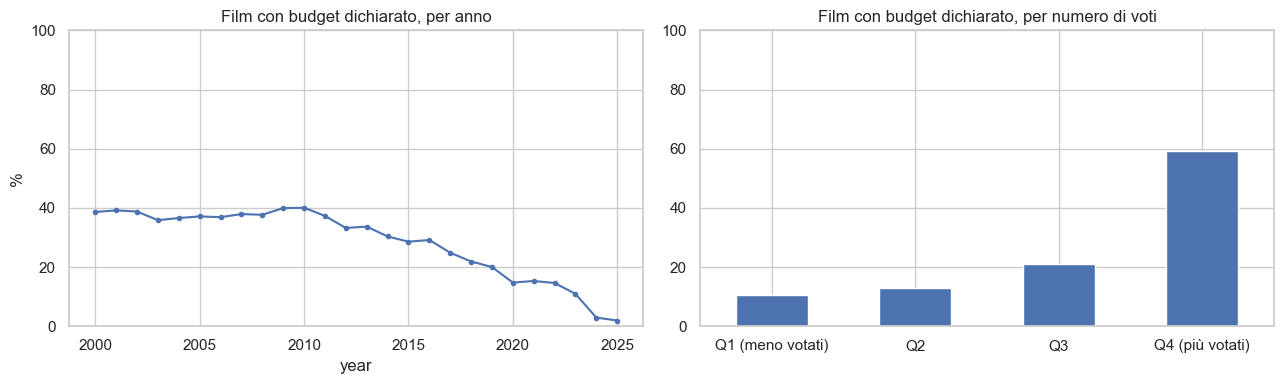

Film con budget dichiarato: 26.0%


In [22]:
eco = movies_final[["year", "imdb_votes"]].copy()
eco["budget_noto"] = movies_final["tmdb_budget"] > 0
eco["quartile_voti"] = pd.qcut(eco["imdb_votes"].rank(method="first"), 4,
                               labels=["Q1 (meno votati)", "Q2", "Q3", "Q4 (più votati)"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(eco.groupby("year")["budget_noto"].mean() * 100).plot(ax=axes[0], marker="o", markersize=3)
axes[0].set_title("Film con budget dichiarato, per anno")
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 100)
(eco.groupby("quartile_voti", observed=True)["budget_noto"].mean() * 100).plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Film con budget dichiarato, per numero di voti")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()

print(f"Film con budget dichiarato: {eco['budget_noto'].mean():.1%}")

Il budget c'è solo per circa un film su quattro, quasi sempre per i film più visti, e sempre meno negli anni recenti.
Un'analisi economica avrebbe descritto solo le grandi produzioni, quindi ho deciso di escluderla.

### 6.2 Volume e gradimento

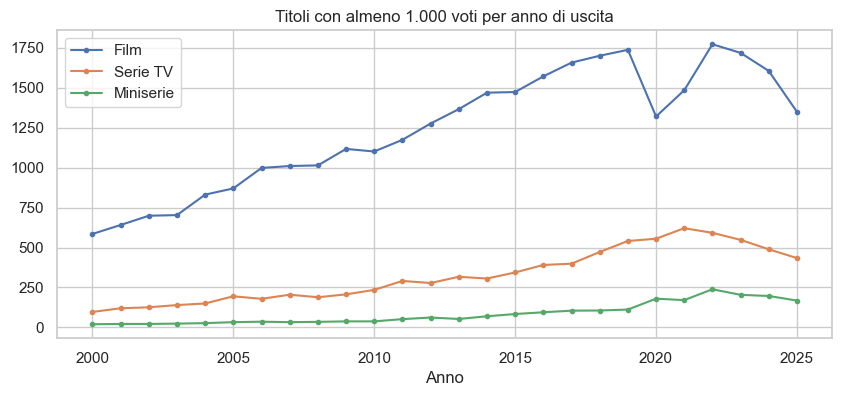

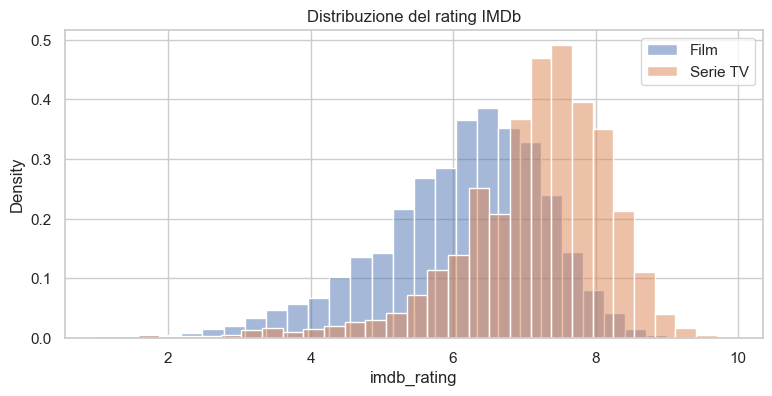

Rating mediano - film: 6.3 | serie TV: 7.3 | miniserie: 7.3


In [23]:
serie_tv = series_final[series_final["title_type"] == "tvSeries"]
miniserie = series_final[series_final["title_type"] == "tvMiniSeries"]

fig, ax = plt.subplots(figsize=(10, 4))
for nome, anni in [("Film", movies_final["year"]), ("Serie TV", serie_tv["start_year"]), ("Miniserie", miniserie["start_year"])]:
    anni.value_counts().sort_index().plot(ax=ax, marker="o", markersize=3, label=nome)
ax.set_title("Titoli con almeno 1.000 voti per anno di uscita")
ax.set_xlabel("Anno")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(movies_final["imdb_rating"], stat="density", bins=30, alpha=0.5, label="Film", ax=ax)
sns.histplot(serie_tv["series_imdb_rating"], stat="density", bins=30, alpha=0.5, label="Serie TV", ax=ax)
ax.set_title("Distribuzione del rating IMDb")
ax.legend()
plt.show()

print("Rating mediano - film:", movies_final["imdb_rating"].median(), "| serie TV:", serie_tv["series_imdb_rating"].median(),
      "| miniserie:", miniserie["series_imdb_rating"].median())

Il calo negli ultimi anni dipende soprattutto dalla soglia dei 1.000 voti: i titoli recenti hanno avuto meno tempo
per accumularli. Le serie hanno un rating mediano più alto dei film (7,3 contro 6,3), in parte per selezione: una
serie arriva a mille voti solo se si costruisce un pubblico fedele.

In [24]:
generi = movies_final[["imdb_id", "genres", "imdb_rating"]].dropna().assign(genere=lambda d: d["genres"].str.split(",")).explode("genere")
tab_generi = generi.groupby("genere")["imdb_rating"].agg(["median", "size"])
tab_generi[tab_generi["size"] >= 30].sort_values("median", ascending=False).head(10)

,median,size
genere,,
Documentary,7.3,2270
Biography,7.0,1982
History,6.8,1308
Music,6.8,986
Animation,6.7,1259
War,6.7,560
Sport,6.7,666
Drama,6.5,17628
Musical,6.5,328


### 6.3 Premi e gradimento

Confronto i titoli con almeno una candidatura collegata con quelli senza.

In [25]:
film_candidati = (movies_final[["oscar_nominations", "golden_globe_nominations", "emmy_anno_categoria_candidate"]].sum(axis=1) > 0)
serie_candidate = (series_final[["golden_globe_nominations", "emmy_anno_categoria_candidate"]].sum(axis=1) > 0)

print(f"Titoli con almeno una candidatura: film {film_candidati.mean():.1%} - serie e miniserie {serie_candidate.mean():.1%}")
print("\nFilm")
print(movies_final.groupby(film_candidati)[["imdb_rating", "imdb_votes"]].median().rename(index={False: "senza", True: "con candidature"}))
print("\nSerie e miniserie")
print(series_final.groupby(serie_candidate)[["series_imdb_rating", "series_imdb_votes"]].median().rename(index={False: "senza", True: "con candidature"}))

Titoli con almeno una candidatura: film 4.3% - serie e miniserie 8.0%

Film
                 imdb_rating  imdb_votes
senza                    6.2      3157.0
con candidature          7.3    101951.0

Serie e miniserie
                 series_imdb_rating  series_imdb_votes
senza                           7.3             2998.0
con candidature                 7.7            26941.5


I titoli candidati hanno un rating più alto (film 7,3 contro 6,2; serie 7,7 contro 7,3) ma anche molti più voti.
Per capire se la differenza dipende solo dalla visibilità, confronto i titoli con e senza candidature dentro ogni
decile del numero di voti, cioè tra titoli con una visibilità simile.

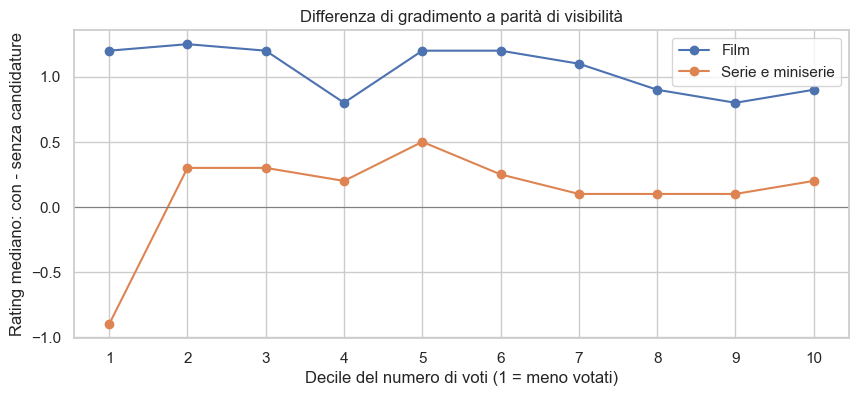

Differenza mediana nei decili con almeno 30 candidati:
film +0.90 | serie +0.10


In [26]:
def per_decile(rating, voti, candidato):
    d = pd.DataFrame({"rating": rating, "voti": voti, "candidato": candidato})
    d["decile"] = pd.qcut(d["voti"].rank(method="first"), 10, labels=range(1, 11))
    t = d.groupby(["decile", "candidato"], observed=True)["rating"].median().unstack()
    t["n_candidati"] = d[d["candidato"]].groupby("decile", observed=True).size()
    t["differenza"] = t[True] - t[False]
    return t


dec_film = per_decile(movies_final["imdb_rating"], movies_final["imdb_votes"], film_candidati)
dec_serie = per_decile(series_final["series_imdb_rating"], series_final["series_imdb_votes"], serie_candidate)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dec_film.index.astype(int), dec_film["differenza"], marker="o", label="Film")
ax.plot(dec_serie.index.astype(int), dec_serie["differenza"], marker="o", label="Serie e miniserie")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decile del numero di voti (1 = meno votati)")
ax.set_ylabel("Rating mediano: con - senza candidature")
ax.set_title("Differenza di gradimento a parità di visibilità")
ax.legend()
plt.show()

print("Differenza mediana nei decili con almeno 30 candidati:")
print(f"film {dec_film.loc[dec_film['n_candidati'] >= 30, 'differenza'].median():+.2f} | "
      f"serie {dec_serie.loc[dec_serie['n_candidati'] >= 30, 'differenza'].median():+.2f}")

Per i film la differenza resta anche a parità di voti (circa 0,9 punti nei decili con almeno 30 candidati, cioè
soprattutto tra i film più votati), per le serie scende a circa un decimo: per le serie buona parte del vantaggio
dipende dalla maggiore visibilità.

C'è però un limite in questo confronto. Il numero di voti non è solo qualcosa che precede la candidatura: in parte ne è
una conseguenza, perché un titolo candidato viene visto e votato di più. Confrontare titoli "a parità di voti" quindi
toglie anche una parte del legame reale, e la differenza che resta va letta come una stima prudente.

### 6.4 Lo stesso confronto con un modello di regressione

Il confronto per decili tiene conto solo della visibilità. Con una regressione lineare posso tenere conto insieme di
anno di uscita, genere e numero di voti. Stimo due modelli per i film e due per le serie:

- **senza i voti**: la differenza tra candidati e non candidati a parità di anno e genere;
- **con il logaritmo dei voti**: la stessa differenza anche a parità di visibilità (uso il logaritmo perché i voti
  vanno da mille a milioni).

Se il coefficiente della candidatura scende molto passando dal primo al secondo modello, buona parte del legame passa
dalla visibilità. Uso errori standard robusti (HC3) perché la variabilità del rating non è la stessa per tutti i titoli.
Per le serie aggiungo il tipo (serie o miniserie). Anche questo modello descrive un'associazione: non dice che la
candidatura faccia salire il voto.

Film
                  effetto  ic95_basso  ic95_alto     R2      n
modello                                                       
senza voti          0.864       0.825      0.904  0.258  32240
con log dei voti    0.301       0.262      0.341  0.303  32240

Serie e miniserie
                  effetto  ic95_basso  ic95_alto     R2      n
modello                                                       
senza voti          0.480       0.421      0.540  0.056  10647
con log dei voti    0.075       0.013      0.136  0.105  10647


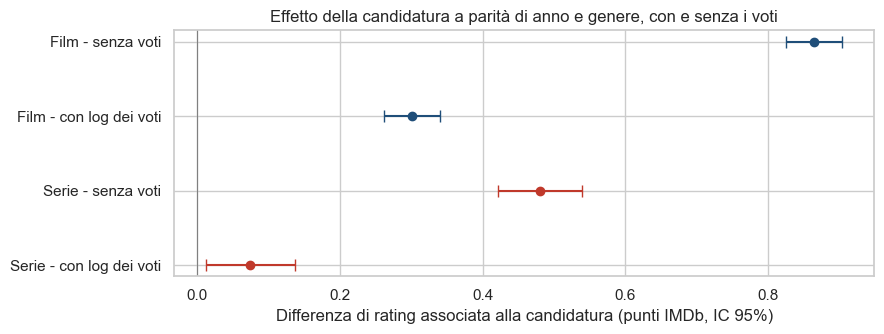

Film: +0.86 punti a parità di anno e genere, +0.30 anche a parità di voti (aggiungendo i voti la differenza si riduce del 65%)
Serie: +0.48 punti a parità di anno e genere, +0.07 anche a parità di voti (aggiungendo i voti la differenza si riduce del 84%)


In [27]:
GENERI_MODELLO = ["Drama", "Comedy", "Action", "Crime", "Thriller", "Horror", "Romance", "Documentary", "Animation"]


def dati_modello(df, col_rating, col_voti, col_anno, candidato):
    d = pd.DataFrame({"rating": df[col_rating], "log_voti": np.log10(df[col_voti]), "anno": df[col_anno],
                      "candidato": candidato.astype(int)})
    generi = df["genres"].fillna("")
    for g in GENERI_MODELLO:
        d["g_" + g] = generi.str.contains(g, regex=False).astype(int)
    return d.dropna()


def stima_effetto(d, extra=""):
    generi = " + ".join(c for c in d.columns if c.startswith("g_") and d[c].nunique() > 1)
    righe = []
    for nome, voti in [("senza voti", ""), ("con log dei voti", " + log_voti")]:
        mod = smf.ols(f"rating ~ candidato{voti} + C(anno) + {generi}{extra}", data=d).fit(cov_type="HC3")
        ic = mod.conf_int().loc["candidato"]
        righe.append({"modello": nome, "effetto": mod.params["candidato"], "ic95_basso": ic.iloc[0],
                      "ic95_alto": ic.iloc[1], "R2": mod.rsquared, "n": int(mod.nobs)})
    return pd.DataFrame(righe).set_index("modello")


d_film = dati_modello(movies_final, "imdb_rating", "imdb_votes", "year", film_candidati)
d_serie = dati_modello(series_final, "series_imdb_rating", "series_imdb_votes", "start_year", serie_candidate)
d_serie["miniserie"] = (series_final.loc[d_serie.index, "title_type"] == "tvMiniSeries").astype(int)

reg_film = stima_effetto(d_film)
reg_serie = stima_effetto(d_serie, extra=" + miniserie")
print("Film\n", reg_film.round(3).to_string(), "\n\nSerie e miniserie\n", reg_serie.round(3).to_string(), sep="")

fig, ax = plt.subplots(figsize=(9, 3.5))
etichette, y = [], 0
for gruppo, tab in [("Film", reg_film), ("Serie", reg_serie)]:
    for modello, r in tab.iterrows():
        ax.errorbar(r["effetto"], y, xerr=[[r["effetto"] - r["ic95_basso"]], [r["ic95_alto"] - r["effetto"]]],
                    fmt="o", color="#1f4e79" if gruppo == "Film" else "#c0392b", capsize=4)
        etichette.append(f"{gruppo} - {modello}")
        y += 1
ax.set_yticks(range(len(etichette)))
ax.set_yticklabels(etichette)
ax.axvline(0, color="grey", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Differenza di rating associata alla candidatura (punti IMDb, IC 95%)")
ax.set_title("Effetto della candidatura a parità di anno e genere, con e senza i voti")
plt.tight_layout()
plt.show()

for gruppo, tab in [("Film", reg_film), ("Serie", reg_serie)]:
    a, b = tab.loc["senza voti", "effetto"], tab.loc["con log dei voti", "effetto"]
    riduzione = f" (aggiungendo i voti la differenza si riduce del {1 - b / a:.0%})" if a > 0 else ""
    print(f"{gruppo}: {a:+.2f} punti a parità di anno e genere, {b:+.2f} anche a parità di voti{riduzione}")

**Come si legge.** Il coefficiente è la differenza media di rating tra titoli candidati e non candidati, a parità delle
altre variabili del modello. Il confronto tra i due modelli dice quanta parte della differenza è legata alla visibilità;
per il motivo spiegato sopra, il secondo modello va letto come una stima prudente.

**Cosa dice.** A parità di anno e genere un film candidato ha in media circa 0,86 punti in più, una serie circa 0,48.
Aggiungendo il numero di voti la differenza scende a circa 0,30 punti per i film e a meno di un decimo per le serie
(0,07, con un intervallo di confidenza che arriva quasi a zero). Il quadro è lo stesso del confronto per decili: per i
film resta un vantaggio chiaro anche a parità di visibilità, per le serie quasi tutto il vantaggio va insieme ai voti.
La regressione dà un valore più basso dei decili per i film perché guarda tutti i titoli e tratta il legame con i
voti come una retta, mentre i decili con molti candidati sono quelli dei film più votati: le due stime vanno lette
insieme, come un intervallo tra circa 0,3 e 0,9 punti.

### 6.5 Popolarità TMDB e miniserie

La popolarità TMDB misura l'attenzione del momento in cui è stato scaricato il dataset, non quanto un film è piaciuto.
Uso Spearman perché voti e popolarità hanno una coda lunghissima.

In [28]:
p = movies_final.dropna(subset=["tmdb_popularity"])
rho, pval = stats.spearmanr(p["tmdb_popularity"], p["imdb_rating"])
print(f"Popolarità TMDB vs rating IMDb: Spearman rho = {rho:.3f}")

for col_mini, nome in [("series_imdb_rating", "rating"), ("series_imdb_votes", "voti")]:
    u, pval = stats.mannwhitneyu(miniserie[col_mini], serie_tv[col_mini])
    r = 2 * u / (len(miniserie) * len(serie_tv)) - 1
    print(f"Miniserie vs serie TV ({nome}): mediane {miniserie[col_mini].median()} vs {serie_tv[col_mini].median()}, "
          f"rank-biserial r = {r:.3f}")

Popolarità TMDB vs rating IMDb: Spearman rho = 0.024
Miniserie vs serie TV (rating): mediane 7.3 vs 7.3, rank-biserial r = 0.047
Miniserie vs serie TV (voti): mediane 3027.5 vs 3381.0, rank-biserial r = -0.050


La correlazione tra popolarità e rating è praticamente nulla. Miniserie e serie TV hanno un gradimento molto simile:
la differenza è trascurabile (r vicino a 0).

## 📺 7. Approfondimento sulle serie: il gradimento stagione per stagione

Uso solo le serie TV con finale osservabile. Le miniserie hanno quasi sempre una sola stagione e le escludo.

### 7.1 Come cambia il gradimento lungo la vita di una serie

Prendo le serie con almeno 4 stagioni con rating e calcolo lo scarto medio dalla media della serie in ciascuna delle
cinque fasi. Ogni serie pesa una volta per fase, così una serie di 20 stagioni non conta più di una di 4.

Serie analizzate: 1116
                  scarto_medio  ic95_basso  ic95_alto  n_serie
fase_serie                                                    
Inizio (0-20%)           0.023       0.004      0.042     1113
20-40%                   0.064       0.046      0.083     1110
40-60%                   0.035       0.009      0.060      701
60-80%                  -0.032      -0.053     -0.011     1105
Finale (80-100%)        -0.074      -0.102     -0.045     1116


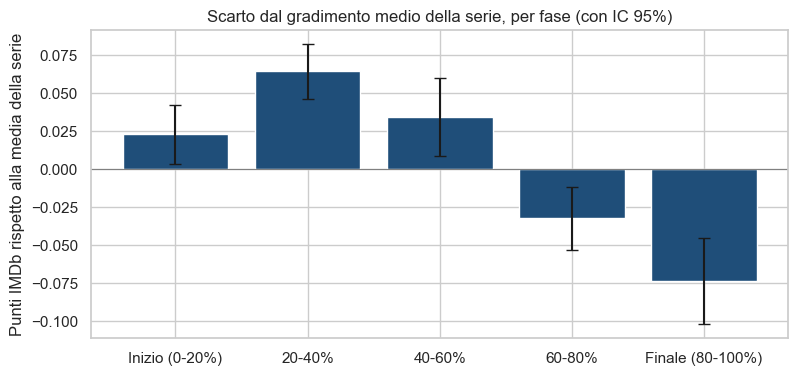

In [29]:
serie_con_finale = set(series_final.loc[series_final["finale_osservabile"] & (series_final["title_type"] == "tvSeries"), "imdb_id"])
st = stagioni[stagioni["series_imdb_id"].isin(serie_con_finale) & stagioni["rating_medio_stagione"].notna()].copy()
n_stag = st.groupby("series_imdb_id")["season_number"].transform("size")
finale_ok = st.groupby("series_imdb_id")["is_stagione_finale"].transform("any")
traiettoria = st[(n_stag >= MIN_STAGIONI) & finale_ok].copy()
traiettoria["scarto"] = (traiettoria["rating_medio_stagione"]
                         - traiettoria.groupby("series_imdb_id")["rating_medio_stagione"].transform("mean"))
print("Serie analizzate:", traiettoria["series_imdb_id"].nunique())


def scarto_per_fase(df):
    per_serie = df.groupby(["fase_serie", "series_imdb_id"])["scarto"].mean().reset_index()
    t = per_serie.groupby("fase_serie")["scarto"].agg(["mean", "std", "count"]).reindex(FASI)
    margine = stats.t.ppf(0.975, t["count"] - 1) * t["std"] / np.sqrt(t["count"])
    return pd.DataFrame({"scarto_medio": t["mean"], "ic95_basso": t["mean"] - margine,
                         "ic95_alto": t["mean"] + margine, "n_serie": t["count"]})


fasi = scarto_per_fase(traiettoria)
print(fasi.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(5), fasi["scarto_medio"], yerr=[fasi["scarto_medio"] - fasi["ic95_basso"], fasi["ic95_alto"] - fasi["scarto_medio"]],
       color="#1f4e79", capsize=4)
ax.set_xticks(range(5))
ax.set_xticklabels(FASI)
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Punti IMDb rispetto alla media della serie")
ax.set_title("Scarto dal gradimento medio della serie, per fase (con IC 95%)")
plt.show()

**Due controlli sulle fasi.**

1. La fase 40-60% contiene meno serie delle altre: in una serie di 4 stagioni le posizioni sono 0, 1/3, 2/3 e 1, e
   nessuna cade tra 0,4 e 0,6. Le cinque fasi quindi non contengono esattamente le stesse serie. Rifaccio il calcolo
   solo con le serie di almeno 5 stagioni, dove ogni fase contiene almeno una stagione.
2. La posizione di una stagione è calcolata dal suo numero. Se a una serie mancano delle stagioni nei dati (per
   esempio 1, 2, 5), il numero e la posizione reale non coincidono. Rifaccio il calcolo usando l'ordine delle
   stagioni con rating (prima, seconda, ..., ultima) invece del loro numero.

In [30]:
# controllo 1: solo le serie con almeno 5 stagioni
lunghe = traiettoria[traiettoria.groupby("series_imdb_id")["season_number"].transform("size") >= 5]
fasi_lunghe = scarto_per_fase(lunghe)

# controllo 2: posizione calcolata sull'ordine delle stagioni invece che sul loro numero
per_ordine = traiettoria.copy()
ordine = per_ordine.groupby("series_imdb_id")["season_number"].rank(method="first")
n_serie = per_ordine.groupby("series_imdb_id")["season_number"].transform("size")
per_ordine["fase_serie"] = pd.cut((ordine - 1) / (n_serie - 1), bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
                                  labels=FASI, include_lowest=True).astype("object")
fasi_ordine = scarto_per_fase(per_ordine)

numeri_con_buchi = (traiettoria.groupby("series_imdb_id")["season_number"].agg(["max", "size"])
                    .pipe(lambda t: t["max"] != t["size"])).sum()
print("Serie con almeno 5 stagioni:", lunghe["series_imdb_id"].nunique())
print("Serie con numeri di stagione non consecutivi:", numeri_con_buchi, "su", traiettoria["series_imdb_id"].nunique())
pd.DataFrame({"almeno 4 stagioni": fasi["scarto_medio"], "n (4+)": fasi["n_serie"],
              "almeno 5 stagioni": fasi_lunghe["scarto_medio"], "n (5+)": fasi_lunghe["n_serie"],
              "posizione per ordine": fasi_ordine["scarto_medio"]}).round(3)

Serie con almeno 5 stagioni: 699
Serie con numeri di stagione non consecutivi: 30 su 1116


,almeno 4 stagioni,n (4+),almeno 5 stagioni,n (5+),posizione per ordine
fase_serie,,,,,
Inizio (0-20%),0.023,1113,0.035,698,0.019
20-40%,0.064,1110,0.078,696,0.066
40-60%,0.035,701,0.041,696,0.041
60-80%,-0.032,1105,-0.049,694,-0.035
Finale (80-100%),-0.074,1116,-0.099,699,-0.072


In [31]:
# lo stesso calcolo per lunghezza della serie
lunghezza = pd.cut(traiettoria.groupby("series_imdb_id")["season_number"].transform("size"),
                   bins=[3, 5, 8, np.inf], labels=["4-5 stagioni", "6-8 stagioni", "9+ stagioni"])
print("Scarto nella fase finale per lunghezza della serie:")
for nome, g in traiettoria.groupby(lunghezza, observed=True):
    print(f"  {nome}: {scarto_per_fase(g).loc['Finale (80-100%)', 'scarto_medio']:+.3f}")

# quante volte la stagione finale è la peggiore o la migliore della serie, rispetto al caso
voto = traiettoria["rating_medio_stagione"].round(6)
gruppo = traiettoria["series_imdb_id"]
finali = traiettoria["is_stagione_finale"]
n = gruppo.map(gruppo.value_counts())
al_min = voto.eq(voto.groupby(gruppo).transform("min"))
al_max = voto.eq(voto.groupby(gruppo).transform("max"))
print(f"\nStagione finale = la peggiore: {al_min[finali].mean():.1%} (per caso: {(al_min.groupby(gruppo).transform('sum') / n)[finali].mean():.1%})")
print(f"Stagione finale = la migliore: {al_max[finali].mean():.1%} (per caso: {(al_max.groupby(gruppo).transform('sum') / n)[finali].mean():.1%})")

Scarto nella fase finale per lunghezza della serie:
  4-5 stagioni: -0.055
  6-8 stagioni: -0.079
  9+ stagioni: -0.151

Stagione finale = la peggiore: 30.7% (per caso: 19.4%)
Stagione finale = la migliore: 24.1% (per caso: 19.6%)


Le prime fasi sono leggermente sopra la media della serie e le ultime leggermente sotto, ma parliamo di pochi
centesimi di punto (al massimo 0,07). I due controlli confermano il quadro: con le sole serie di almeno 5 stagioni
l'andamento è lo stesso (un po' più marcato), e calcolando la posizione sull'ordine delle stagioni invece che sul
loro numero i valori cambiano di pochi millesimi, anche perché solo 30 serie su 1.116 hanno numeri di stagione non
consecutivi. Il calo finale cresce con la lunghezza della serie. La stagione finale è più
spesso del previsto sia la peggiore sia la migliore della serie.

### 7.2 L'ultima stagione delude?

Per ogni serie con finale osservabile confronto il rating della stagione finale con la media delle stagioni
precedenti (pesata per numero di episodi con rating). È un confronto appaiato: ogni serie è confrontata con se stessa.
Uso il t-test sulla media delle differenze e il Wilcoxon, che è meno sensibile ai valori estremi. Con migliaia di
serie anche differenze minime risultano significative, quindi guardo soprattutto quanto è grande l'effetto (Cohen's d).

In [32]:
def differenza_ultima_stagione(g):
    finale, precedenti = g[g["is_stagione_finale"]]["rating_medio_stagione"], g[~g["is_stagione_finale"]]
    peso = precedenti["n_episodi_con_rating"].sum()
    if len(finale) == 0 or peso <= 0:
        return np.nan
    return finale.max() - (precedenti["rating_medio_stagione"] * precedenti["n_episodi_con_rating"]).sum() / peso


differenze = st.groupby("series_imdb_id")[["is_stagione_finale", "rating_medio_stagione", "n_episodi_con_rating"]] \
    .apply(differenza_ultima_stagione).dropna()
stagioni_con_rating = st.groupby("series_imdb_id").size()


def confronto(diff, nome):
    ic = stats.t.interval(0.95, len(diff) - 1, loc=diff.mean(), scale=stats.sem(diff))
    print(f"{nome}: {len(diff)} serie | differenza media {diff.mean():+.3f} (IC 95% {ic[0]:+.3f}; {ic[1]:+.3f}) "
          f"| mediana {diff.median():+.3f} | Cohen's d {diff.mean() / diff.std():.3f} "
          f"| t-test p = {stats.ttest_1samp(diff, 0).pvalue:.2g} | Wilcoxon p = {stats.wilcoxon(diff).pvalue:.2g}")


confronto(differenze, "Tutte le serie")
confronto(differenze[stagioni_con_rating.reindex(differenze.index) >= MIN_STAGIONI], "Almeno 4 stagioni")
print(f"Serie con finale sotto la media delle precedenti: {(differenze < 0).mean():.1%}")

Tutte le serie: 3258 serie | differenza media -0.036 (IC 95% -0.056; -0.016) | mediana +0.007 | Cohen's d -0.061 | t-test p = 0.00052 | Wilcoxon p = 0.37
Almeno 4 stagioni: 1116 serie | differenza media -0.091 (IC 95% -0.130; -0.051) | mediana -0.037 | Cohen's d -0.136 | t-test p = 6.6e-06 | Wilcoxon p = 0.00014
Serie con finale sotto la media delle precedenti: 48.9%


In [33]:
# i cali più forti (almeno 2 punti), ordinati per numero di voti della serie
cali = differenze[differenze <= -2].to_frame("differenza").join(
    series_final.set_index("imdb_id")[["title", "start_year", "end_year", "series_imdb_votes"]])
print("Serie che perdono almeno 2 punti nella stagione finale:", len(cali))
cali.sort_values("series_imdb_votes", ascending=False).head(10).round(2)

Serie che perdono almeno 2 punti nella stagione finale: 34


,differenza,title,start_year,end_year,series_imdb_votes
series_imdb_id,,,,,
tt0944947,-2.55,Game of Thrones,2011,2019.0,2665117.0
tt1856010,-4.27,House of Cards,2013,2018.0,563684.0
tt0369179,-2.01,Two and a Half Men,2003,2015.0,301045.0
tt1628033,-2.07,Top Gear,2002,2022.0,138290.0
tt4635276,-2.54,Master of None,2015,2021.0,79155.0
tt8788458,-2.28,The Promised Neverland,2019,2021.0,60219.0
tt0383126,-2.68,MythBusters,2003,2018.0,56980.0
tt0235918,-2.14,The Fairly OddParents,2001,2017.0,53050.0
tt3921180,-2.28,Scream: The TV Series,2015,2019.0,48868.0


La distribuzione delle differenze mostra perché media e mediana non coincidono: quasi tutte le serie stanno vicino allo
zero, con una coda di finali molto peggiori delle stagioni precedenti.

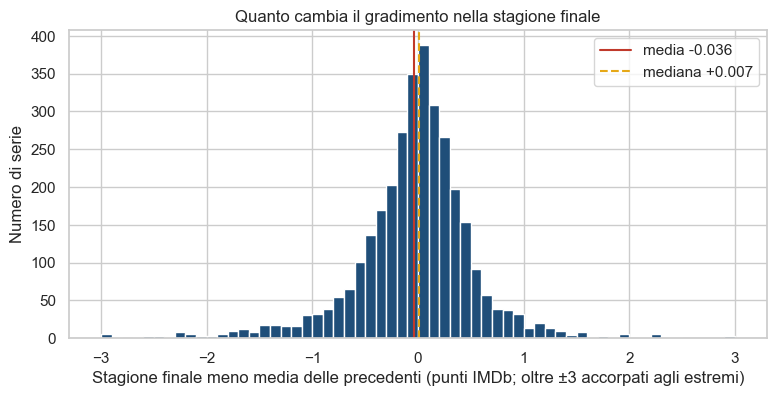

In [34]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(differenze.clip(-3, 3), bins=60, color="#1f4e79")
ax.axvline(differenze.mean(), color="#c0392b", lw=1.5, label=f"media {differenze.mean():+.3f}")
ax.axvline(differenze.median(), color="#e6a817", lw=1.5, ls="--", label=f"mediana {differenze.median():+.3f}")
ax.set_xlabel("Stagione finale meno media delle precedenti (punti IMDb; oltre ±3 accorpati agli estremi)")
ax.set_ylabel("Numero di serie")
ax.set_title("Quanto cambia il gradimento nella stagione finale")
ax.legend()
plt.show()

In media l'ultima stagione vale appena 0,036 punti meno delle precedenti. Il t-test la considera significativa, il
Wilcoxon no, e l'effetto è trascurabile (d = -0,06). La differenza mediana è addirittura positiva (+0,007): la serie
tipica non finisce peggio, la media è trascinata giù da pochi crolli molto forti come House of Cards (-4,27) e
Game of Thrones (-2,55). Considerando solo le serie con almeno 4 stagioni il calo sale a 0,09 punti e lo confermano
entrambi i test, ma resta piccolo.

## 📈 8. Tabelle per la dashboard Power BI

Preparo qui le 8 tabelle lette da Power BI, nella cartella `powerbi/`. All'inizio facevo questi passaggi in Power
Query, ma con oltre 600 mila episodi la numerazione era troppo lenta, quindi li ho spostati in Python.
I passaggi: film e serie in un'unica tabella dei titoli, un genere per riga, episodi numerati serie per serie, e due
colonne per l'approfondimento sulle serie. Al posto dei codici delle lingue metto il nome in italiano. Ogni cella prepara una tabella (o un gruppo di tabelle
collegate), l'ultima le salva.

In [35]:
leggi = lambda f: pd.read_csv(OUT + f, low_memory=False, keep_default_na=False, na_values=[""])
m, s = leggi("movies_final.csv"), leggi("series_final.csv")
st_csv, e, p = leggi("stagioni_serie.csv"), leggi("episodes_final.csv"), leggi("premi_titoli_dettaglio.csv")
FONTI = {"oscar": "Oscar", "golden_globe": "Golden Globe", "emmy": "Emmy"}

NOMI_LINGUE = {
    "af": "Afrikaans", "am": "Amarico", "ar": "Arabo", "as": "Assamese", "ay": "Aymara", "az": "Azero",
    "bg": "Bulgaro", "bm": "Bambara", "bn": "Bengalese", "bo": "Tibetano", "bs": "Bosniaco", "ca": "Catalano",
    "cn": "Cantonese", "cs": "Ceco", "cy": "Gallese", "da": "Danese", "de": "Tedesco", "dz": "Dzongkha",
    "el": "Greco", "en": "Inglese", "es": "Spagnolo", "et": "Estone", "eu": "Basco", "fa": "Persiano",
    "fi": "Finlandese", "fr": "Francese", "ga": "Irlandese", "gl": "Galiziano", "gu": "Gujarati", "he": "Ebraico",
    "hi": "Hindi", "hr": "Croato", "hu": "Ungherese", "hy": "Armeno", "id": "Indonesiano", "is": "Islandese",
    "it": "Italiano", "iu": "Inuktitut", "ja": "Giapponese", "jv": "Giavanese", "ka": "Georgiano", "kk": "Kazako",
    "km": "Khmer", "kn": "Kannada", "ko": "Coreano", "ku": "Curdo", "ky": "Kirghiso", "la": "Latino", "lo": "Lao",
    "lt": "Lituano", "lv": "Lettone", "mi": "Maori", "mk": "Macedone", "ml": "Malayalam", "mn": "Mongolo",
    "mr": "Marathi", "ms": "Malese", "mt": "Maltese", "my": "Birmano", "nb": "Norvegese (bokmål)", "ne": "Nepalese",
    "nl": "Olandese", "no": "Norvegese", "or": "Oriya", "pa": "Punjabi", "pl": "Polacco", "ps": "Pashto",
    "pt": "Portoghese", "qu": "Quechua", "ro": "Rumeno", "ru": "Russo", "rw": "Kinyarwanda", "se": "Sami del nord",
    "sh": "Serbo-croato", "si": "Singalese", "sk": "Slovacco", "sl": "Sloveno", "sq": "Albanese", "sr": "Serbo",
    "st": "Sotho", "sv": "Svedese", "sw": "Swahili", "ta": "Tamil", "te": "Telugu", "th": "Thailandese",
    "tl": "Tagalog", "tn": "Tswana", "tr": "Turco", "uk": "Ucraino", "ur": "Urdu", "vi": "Vietnamita",
    "wo": "Wolof", "xh": "Xhosa", "xx": "Nessuna lingua", "yi": "Yiddish", "zh": "Cinese", "zu": "Zulu",
}

In [36]:
# --- Titoli: film, serie TV e miniserie insieme ---
film_pbi = pd.DataFrame({
    "imdb_id": m.imdb_id, "Titolo": m.title, "Tipo": "Film", "Anno": m.year, "Anno fine": np.nan,
    "Durata (min)": m.runtime_minutes, "Generi": m.genres, "Rating": m.imdb_rating, "Voti": m.imdb_votes,
    "Oscar cand.": m.oscar_nominations, "Oscar vinti": m.oscar_wins,
    "Golden Globe cand.": m.golden_globe_nominations, "Golden Globe vinti": m.golden_globe_wins,
    "Emmy cand.": m.emmy_anno_categoria_candidate, "Emmy vinti": m.emmy_anno_categoria_vinte,
    "Popolarità TMDB": m.tmdb_popularity, "Lingua originale": m.original_language.map(NOMI_LINGUE).fillna("Non disponibile"),
    "Paesi di produzione": m.production_countries, "Casa di produzione": m.first_production_company,
    "Regista": m.director, "Numero stagioni": np.nan, "Stato serie": None, "Finale osservabile": None})
serie_pbi = pd.DataFrame({
    "imdb_id": s.imdb_id, "Titolo": s.title, "Tipo": np.where(s.title_type == "tvMiniSeries", "Miniserie", "Serie TV"),
    "Anno": s.start_year, "Anno fine": s.end_year, "Durata (min)": np.nan, "Generi": s.genres,
    "Rating": s.series_imdb_rating, "Voti": s.series_imdb_votes, "Oscar cand.": np.nan, "Oscar vinti": np.nan,
    "Golden Globe cand.": s.golden_globe_nominations, "Golden Globe vinti": s.golden_globe_wins,
    "Emmy cand.": s.emmy_anno_categoria_candidate, "Emmy vinti": s.emmy_anno_categoria_vinte,
    "Popolarità TMDB": np.nan, "Lingua originale": None, "Paesi di produzione": None, "Casa di produzione": None,
    "Regista": None, "Numero stagioni": s.num_stagioni, "Stato serie": s.stato_serie,
    "Finale osservabile": s.finale_osservabile})
titoli_pbi = pd.concat([film_pbi, serie_pbi], ignore_index=True)
titoli_pbi["Macro tipo"] = np.where(titoli_pbi.Tipo == "Film", "Film", "Serie")
titoli_pbi["Ordine tipo"] = titoli_pbi.Tipo.map({"Film": 1, "Serie TV": 2, "Miniserie": 3})
titoli_pbi["Ha candidatura"] = titoli_pbi[["Oscar cand.", "Golden Globe cand.", "Emmy cand."]].fillna(0).sum(axis=1) > 0
titoli_pbi["Gruppo candidature"] = np.where(titoli_pbi["Ha candidatura"], "Con candidature", "Senza candidature")
titoli_pbi["Titolo (Anno)"] = titoli_pbi.Titolo.astype(str) + " (" + titoli_pbi.Anno.astype(int).astype(str) + ")"
titoli_pbi["Fascia rating"] = np.floor(titoli_pbi.Rating * 2) / 2

# colonne per l'approfondimento sulle serie (stesse regole della sezione 7)
st_rating = st_csv[st_csv.rating_medio_stagione.notna()]
per_serie = st_rating.groupby("series_imdb_id")
n_stagioni_rating, finale_con_rating = per_serie.size(), per_serie.is_stagione_finale.any()
con_finale = set(titoli_pbi.loc[(titoli_pbi.Tipo == "Serie TV") & (titoli_pbi["Finale osservabile"] == True), "imdb_id"])
in_traiettoria = {i for i in n_stagioni_rating.index
                  if i in con_finale and n_stagioni_rating[i] >= MIN_STAGIONI and finale_con_rating[i]}
titoli_pbi["In traiettoria"] = titoli_pbi.imdb_id.isin(in_traiettoria)
diff_pbi = st_rating[st_rating.series_imdb_id.isin(con_finale)].groupby("series_imdb_id")[
    ["is_stagione_finale", "rating_medio_stagione", "n_episodi_con_rating"]].apply(differenza_ultima_stagione).dropna()
titoli_pbi["Differenza ultima stagione"] = titoli_pbi.imdb_id.map(diff_pbi)

In [37]:
# --- Generi: uno per riga ---
generi_pbi = titoli_pbi[["imdb_id", "Generi"]].dropna()
generi_pbi = generi_pbi.assign(Genere=generi_pbi.Generi.str.split(",")).explode("Genere")[["imdb_id", "Genere"]]

In [38]:
# --- Stagioni ---
stagioni_pbi = pd.DataFrame({
    "series_imdb_id": st_csv.series_imdb_id, "Stagione": st_csv.season_number, "N episodi": st_csv.n_episodi,
    "Episodi con rating": st_csv.n_episodi_con_rating, "Rating stagione": st_csv.rating_medio_stagione,
    "Voti stagione": st_csv.voti_totali_stagione, "Ultima disponibile": st_csv.is_ultima_stagione_disponibile,
    "Stagione finale": st_csv.is_stagione_finale, "Ruolo stagione": st_csv.ruolo_stagione, "Fase": st_csv.fase_serie,
    "Scarto dalla media della serie": st_csv.scarto_dalla_media_serie})
stagioni_pbi["Ordine fase"] = stagioni_pbi.Fase.map({f: i for i, f in enumerate(FASI, start=1)})

In [39]:
# --- Episodi: numero progressivo dentro ogni serie, per il grafico episodio per episodio ---
episodi_pbi = pd.DataFrame({
    "series_imdb_id": e.series_imdb_id, "Stagione": e.season_number, "Episodio": e.episode_number,
    "Anno episodio": e.episode_year, "Rating episodio": e.episode_rating, "Voti episodio": e.episode_votes})
episodi_pbi = episodi_pbi.sort_values(["series_imdb_id", "Stagione", "Episodio"], kind="mergesort")
episodi_pbi["Progressivo"] = np.where(episodi_pbi.Stagione.notna(), episodi_pbi.groupby("series_imdb_id").cumcount() + 1, np.nan)
episodi_pbi.loc[episodi_pbi.Stagione.isna(), "Progressivo"] = np.nan
episodi_pbi["Fascia rating episodio"] = np.floor(episodi_pbi["Rating episodio"] * 2) / 2

In [40]:
# --- Premi ---
premi_pbi = pd.DataFrame({
    "Categoria": p.categoria, "Anno premio": p.anno_premio, "Anno opera": p.anno_opera,
    "Titolo nella fonte": p.titolo_fonte, "Persona nella fonte": p.persona_fonte, "Vinto": p.vinto,
    "Righe fonte": p.righe_fonte, "imdb_id": p.imdb_id, "Titolo IMDb": p.titolo_imdb,
    "Esito collegamento": p.esito_match, "Fonte": p.fonte.map(FONTI), "Ambito": p.ambito.map({"film": "Film", "serie": "Serie"})})
premi_pbi["Collegato"] = premi_pbi["Esito collegamento"] == "collegato"

In [41]:
# --- Cast, registi e candidature delle persone ---
cast_csv = pd.concat([leggi("movies_cast.csv"), leggi("series_cast.csv")])
cast_pbi = pd.DataFrame({"imdb_id": cast_csv.imdb_id, "nconst": cast_csv.nconst, "Persona": cast_csv.attore,
                         "Rango": cast_csv.rango_attore, "Ruolo": np.where(cast_csv.ruolo == "actress", "Attrice", "Attore")})
reg = leggi("movies_directors.csv")
registi_pbi = pd.DataFrame({"imdb_id": reg.imdb_id, "director_nconst": reg.director_nconst, "Regista": reg.director})
nom = pd.concat([leggi("attori_nomination_dettaglio.csv"), leggi("registi_nomination_dettaglio.csv")])
nomination_pbi = pd.DataFrame({
    "Categoria": nom.categoria, "Anno premio": nom.anno_premio, "imdb_id": nom.imdb_id,
    "persona_nconst": nom.persona_nconst, "Persona": nom.persona_nome_imdb, "Vinto": nom.vinto,
    "Titolo IMDb": nom.titolo_imdb, "Fonte": nom.fonte.map(FONTI),
    "Ruolo premiato": np.where(nom.ruolo == "regista", "Regista", "Interprete")})

In [42]:
# interi senza decimali e valori logici come True/False, così Power BI riconosce bene i tipi
DECIMALI = {"Rating", "Rating stagione", "Rating episodio", "Scarto dalla media della serie",
            "Differenza ultima stagione", "Popolarità TMDB", "Fascia rating", "Fascia rating episodio"}


def per_power_bi(df):
    df = df.copy()
    for col in df.columns:
        valori = df[col].dropna()
        if df[col].dtype == bool or (df[col].dtype == object and len(valori) and valori.isin([True, False]).all()):
            df[col] = df[col].map({True: "True", False: "False"})
        elif pd.api.types.is_float_dtype(df[col]) and (valori == valori.round()).all() and col not in DECIMALI:
            df[col] = df[col].astype("Int64")
    return df


tabelle = {"Titoli": titoli_pbi, "Titoli_Generi": generi_pbi, "Stagioni": stagioni_pbi, "Episodi": episodi_pbi,
           "Premi": premi_pbi, "Cast": cast_pbi, "Registi": registi_pbi, "Nomination_Persone": nomination_pbi}
for nome, df in tabelle.items():
    per_power_bi(df).to_csv(OUT_PBI + nome + ".csv", index=False, lineterminator="\n")
    print(f"powerbi/{nome}.csv: {len(df)} righe, {df.shape[1]} colonne")

powerbi/Titoli.csv: 42887 righe, 31 colonne
powerbi/Titoli_Generi.csv: 99157 righe, 2 colonne
powerbi/Stagioni.csv: 27803 righe, 12 colonne
powerbi/Episodi.csv: 638794 righe, 8 colonne
powerbi/Premi.csv: 14647 righe, 13 colonne
powerbi/Cast.csv: 197076 righe, 5 colonne
powerbi/Registi.csv: 36279 righe, 3 colonne
powerbi/Nomination_Persone.csv: 3641 righe, 9 colonne


## 🏁 9. Conclusioni e limiti

**1. Gradimento e premi.** Le serie hanno un rating mediano più alto dei film (7,3 contro 6,3), ma in parte è un effetto
della soglia: una serie supera i mille voti solo se ha un pubblico fedele. I premi riguardano pochi titoli: ha almeno
una candidatura collegata circa il 4% dei film e l'8% di serie e miniserie.

**2. Pubblico e critica.** I titoli candidati hanno un rating più alto (film 7,3 contro 6,2; serie 7,7 contro 7,3) e
molti più voti. A parità di numero di voti per i film resta un vantaggio tra circa 0,3 punti (regressione della
sezione 6.4, che tiene conto anche di anno e genere) e 0,9 punti (confronto per decili); per le serie resta circa un
decimo. La popolarità TMDB non è legata al gradimento, e miniserie e serie TV hanno un gradimento molto simile.
I numeri chiave sono riassunti nella cella qui sotto.

**3. Le serie nel tempo.** Il gradimento cambia poco lungo la vita di una serie. L'ultima stagione vale in media 0,036
punti meno delle precedenti, ma la serie tipica non cala (mediana +0,007): la media scende per pochi crolli come House of
Cards e Game of Thrones. Il calo è un po' più forte nelle serie lunghe (0,09 punti con almeno 4 stagioni).

**Limiti**
- I voti IMDb sono di chi sceglie di votare e si accumulano nel tempo: i titoli più vecchi hanno avuto più tempo.
- I premi contati sono quelli collegati automaticamente, quindi sono un minimo; per gli Emmy conto le combinazioni
  titolo-anno-categoria. Nel controllo a campione della sezione 3.5 i collegamenti trovati sono risultati
  corretti: il problema dei premi è quanti collegamenti mancano, non quanti sono sbagliati.
- Dal 2022 le candidature Emmy per serie vengono da Wikipedia, che riporta meno categorie del dataset originale:
  il calo degli Emmy negli ultimi anni dipende dalla fonte, non è un trend, e le serie più recenti hanno meno
  candidature Emmy di quelle che hanno avuto davvero.
- Il numero di voti è in parte una conseguenza della candidatura: i confronti a parità di voti sono prudenti.
- Il rating degli episodi c'è soprattutto per le serie più seguite, e l'analisi delle stagioni riguarda soprattutto quelle.
- Con i dati IMDb non si distinguono le serie concluse da quelle cancellate.
- Budget e incassi sono esclusi perché noti solo per circa un film su quattro.
- Tutti i risultati descrivono associazioni, non rapporti di causa ed effetto.


In [43]:
# i numeri chiave del progetto, presi dalle sezioni precedenti
reg = {g: (t.loc["senza voti", "effetto"], t.loc["con log dei voti", "effetto"]) for g, t in [("film", reg_film), ("serie", reg_serie)]}
print(f"Catalogo: {len(movies_final)} film, {len(serie_tv)} serie TV, {len(miniserie)} miniserie (2000-2025, almeno 1.000 voti)")
print(f"Candidature collegate nel periodo: {(premi['esito_match'] == 'collegato').mean():.0%}")
if pd.notna(PRECISIONE):
    print(f"Precisione dei collegamenti: {PRECISIONE:.0%} (limite inferiore prudente {PRECISIONE_MIN:.0%})")
print(f"Titoli candidati: film {film_candidati.mean():.1%}, serie e miniserie {serie_candidate.mean():.1%}")
print(f"Rating mediano con e senza candidature: film {movies_final.loc[film_candidati, 'imdb_rating'].median()} contro "
      f"{movies_final.loc[~film_candidati, 'imdb_rating'].median()}, serie {series_final.loc[serie_candidate, 'series_imdb_rating'].median()} "
      f"contro {series_final.loc[~serie_candidate, 'series_imdb_rating'].median()}")
print(f"Regressione, a parità di anno e genere: film {reg['film'][0]:+.2f}, serie {reg['serie'][0]:+.2f} punti; "
      f"anche a parità di voti: film {reg['film'][1]:+.2f}, serie {reg['serie'][1]:+.2f}")
print(f"Ultima stagione: {differenze.mean():+.3f} punti in media, mediana {differenze.median():+.3f} ({len(differenze)} serie)")

Catalogo: 32240 film, 8421 serie TV, 2226 miniserie (2000-2025, almeno 1.000 voti)
Candidature collegate nel periodo: 76%
Precisione dei collegamenti: 100% (limite inferiore prudente 93%)
Titoli candidati: film 4.3%, serie e miniserie 8.0%
Rating mediano con e senza candidature: film 7.3 contro 6.2, serie 7.7 contro 7.3
Regressione, a parità di anno e genere: film +0.86, serie +0.48 punti; anche a parità di voti: film +0.30, serie +0.07
Ultima stagione: -0.036 punti in media, mediana +0.007 (3258 serie)
